# Traditional Image Analysis of Grape Bunch Detection
### Color Segmentation + Handcrafted Features (CLAHE, Gabor, LBP, HOG, Blob-Shape, Haralick, Canny) + SVM / XGBoost / Random Forest / Ensemble - Detecting and Counting Grape Bunches

This notebook is a self-contained traditional computer-vision pipeline. It does not depend on any other project notebook or dataset. Unlike a whole-image classifier (one label per image), the goal here is *detection and counting*: given a field photo, find every grape bunch in it and report how many there are. That requires an extra piece that pure classification never needs - a way to propose *where* a bunch might be before anything gets classified. Phase 2.2 (color segmentation) is that piece.

# Phase 0 - Environment Setup

## 0.0 Configure Base Path

Run exactly ONE of the next two cells, matching where this notebook is executing - not both. Everything after Phase 0 only depends on `BASE_DIR` being set correctly, so the rest of the notebook does not care which option was used.

### Option A - Google Colab (mounts Drive)

Use this if the dataset and/or farm photos live in Google Drive.

In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

BASE_DIR = Path("drive/MyDrive/GrapeBunchDetection_Traditional")
FARM_IMAGES_DIR = BASE_DIR / "data" / "raw"  # real farm photos -- upload the local LiveImages/ folder's contents here
print(f"Running on Colab. BASE_DIR = {BASE_DIR.resolve()}")

### Option B - Local machine (no Drive mount)

Use this if the notebook and the `grape_bunch_dataset/` folder sit together locally, and the real farm photos sit in `LiveImages/` at the repo root, one level above this notebook's folder - nothing gets mounted, everything is read straight off disk.

In [ ]:
from pathlib import Path

# No Google Drive mount - everything is read from folders sitting next to this notebook.
BASE_DIR = Path(".")
FARM_IMAGES_DIR = BASE_DIR.resolve().parent / "LiveImages"  # real farm photos: LiveImages/ at the repo root, one level above this notebook

assert FARM_IMAGES_DIR.exists(), (
    f"Expected the real farm photos folder at {FARM_IMAGES_DIR.resolve()} - "
    f"create/rename it, or switch to Option A if your data lives in Drive instead."
)
n_farm_imgs = len([p for p in FARM_IMAGES_DIR.glob("*.*") if p.suffix.lower() in (".jpg", ".jpeg", ".png")])

print(f"Running locally (no Drive mount). BASE_DIR = {BASE_DIR.resolve()}")
print(f"Farm images folder: {FARM_IMAGES_DIR.resolve()}  ({n_farm_imgs} images found)")

## 0.1 Library Installation & Imports

### Install required packages (run once, then comment out)

In [ ]:
# Install required packages (run once, then comment out)
!pip install pandas opencv-python scikit-image scikit-learn matplotlib seaborn tqdm pillow scipy numpy xgboost shap plt

### Import core libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os
import random
import time
import json
import pickle
import warnings
import joblib
warnings.filterwarnings("ignore")

from pathlib import Path
from tqdm import tqdm
from PIL import Image, ImageDraw
from scipy.stats import chi2

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold,
    cross_val_score, learning_curve,
)
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    average_precision_score, roc_auc_score,
)

import xgboost as xgb
import shap
from skimage.feature import hog, local_binary_pattern, graycomatrix

print("All imports OK.")

## 0.2 Global Configuration

### Set random seeds and define project constants

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

CLASS_NAMES = ["background", "grape_bunch"]
NUM_CLASSES = len(CLASS_NAMES)
PATCH_SIZE = (128, 128)          # size every patch is resized to before feature extraction

TRAIN_RATIO = 0.6
VAL_RATIO = 0.2
TEST_RATIO = 0.2
CV_FOLDS = 5

NEG_PER_BOX = 2                  # background patches sampled per ground-truth bunch box
IOU_NEG_MAX = 0.10               # a random crop only counts as "background" if it barely touches any GT box

CERTH_PREFIX = "CERTH_"          # marks the CERTH Grape Dataset subset (see Phase 1.2) for stratified splitting
COUNTING_SAMPLE_SIZE = 200       # Phase 6.5 evaluates a stratified sample instead of all 2,500+ test images (would take hours otherwise)

NMS_IOU_THRESH = 0.30            # merge overlapping detections above this mutual IoU
NMS_CONTAINMENT_THRESH = 0.70    # symmetric: a box this contained inside ANOTHER candidate (either
                                  # direction) is redundant with it, regardless of which one the
                                  # classifier scored higher - see Phase 6.2 for why. Calibrated from
                                  # real candidates: genuine same-bunch fragments measured ~100% mutual
                                  # containment; distinct adjacent bunches in dense multi-bunch photos
                                  # measured <=66% even at their most overlapping pair.
DETECTION_CONF_THRESH = 0.50     # candidate region must score above this to be kept as a detected bunch

# Phase 2.2b's own recall audit found the contour-based proposer was capturing <1.1% of ground-truth
# bunches (leaf canopy and bunches share the same HSV range and fuse into one blob that fails the
# max-area cutoff). These parameters drive the sliding-window replacement instead. Window sizes are
# derived from the actual bunch-size-as-fraction-of-image distribution of the CURRENT dataset (Zenodo
# close-ups run ~20-88% of frame width; CERTH in-vineyard shots run ~9-44%) - measured directly via
# percentiles per source and spanning both, since a set of scales tuned to only one source (as an
# earlier version was, against a since-removed dataset) leaves the other with near-zero proposal
# recall: a window capped at 10% of the frame can never reach worthwhile IoU against a bunch that
# fills 60%+ of a close-up photo, no matter how well it's centered.
PROPOSAL_WINDOW_SCALES = [
    (0.10, 0.08),   # CERTH ~p10
    (0.16, 0.13),   # CERTH ~p25-p50
    (0.27, 0.22),   # CERTH ~p75
    (0.40, 0.38),   # CERTH ~p90 / Zenodo ~p10 bridge
    (0.58, 0.62),   # Zenodo ~p25-p50
    (0.78, 0.82),   # Zenodo ~p75-p90
]  # (width_frac, height_frac)
PROPOSAL_STRIDE_FRAC = 0.75      # stride as a fraction of window size (smaller = more overlap = higher recall, slower)
PROPOSAL_MIN_COVERAGE = 0.05     # min fraction of a window's pixels that must pass the color mask to keep it

print(f"Classes: {CLASS_NAMES}")
print(f"Patch size: {PATCH_SIZE}")
print(f"Split: train={TRAIN_RATIO:.0%}  val={VAL_RATIO:.0%}  test={TEST_RATIO:.0%}")


---
# Phase 1 - Dataset Preparation & EDA

## 1.1 Data Acquisition

### Load the bounding-box annotated grape bunch dataset

Expected layout: `DATASET_DIR/images/*.jpg` + `DATASET_DIR/labels/*.txt`, one YOLO-format label file per image (`class cx cy w h`, all normalized 0-1, one line per bunch). Every class id is collapsed down to a single "bunch" concept - cultivar/variety/maturity is not the point, only presence and location. If your download already ships as separate train/val/test folders instead of one flat pool, point `IMAGES_DIR`/`LABELS_DIR` at each split directly and skip the random split in 1.3.

**Composition (as of this version):** this pool is a merge of two sources, both CC BY 4.0 (commercial use permitted with attribution), converted to the same flat YOLO format:
- **10,010 images** - close-up, mostly single-bunch, green-dominant photos (~1,820 unique base photos + 8 augmentation variants each: flip/blur/noise/scale/translate/angle/etc). This is the [Zenodo "Grapevine Bunch Detection Dataset"](https://zenodo.org/records/7717055) (720x540).
- **2,587 images** (prefixed `CERTH_`) - real in-vineyard iPhone photos of Crimson Seedless table grapes across three maturity stages (immature/semi-mature/mature), 2160x3840, ~9,917 bunch boxes, converted here from the original COCO-format masks/bboxes. This is the [CERTH Grape Dataset](https://zenodo.org/records/10777647) - its "Mature" class (70% of its train annotations) is red/crimson-toned, which is the color-domain diversity this merge was specifically chosen to add (see Phase 8 for why: this pipeline's earlier all-green training data produced near-zero detections on real farm photos).

An earlier version also merged in 300 [Embrapa WGISD](https://github.com/thsant/wgisd) images (wide trellis-system framing, 5 cultivars), which was the best framing match to the real farm photos in `LiveImages/` but is CC BY-NC 4.0 (non-commercial only) - removed since this project may be used commercially (see `excluded_nc_licensed_data/README.md`). CERTH does not fully replace that framing match (its photos are closer single-bunch/small-cluster shots, not wide multi-bunch trellis rows), so Phase 8's real-farm domain gap may still be partially open on the framing/occlusion axis even though the color axis is now addressed.


In [ ]:
DATASET_DIR = BASE_DIR / "grape_bunch_dataset"
IMAGES_DIR = DATASET_DIR / "images"
LABELS_DIR = DATASET_DIR / "labels"
MODELS_DIR = BASE_DIR / "saved_models"
MODELS_DIR.mkdir(exist_ok=True, parents=True)
CV_CACHE_FOLDER = BASE_DIR / "cross_validation_cache"
CV_CACHE_FOLDER.mkdir(exist_ok=True, parents=True)
CV_CACHE_DIR = CV_CACHE_FOLDER / "cv_results_cache.pkl"
LC_CACHE_FOLDER = BASE_DIR / "learning_curve_cache"
LC_CACHE_FOLDER.mkdir(exist_ok=True, parents=True)
LC_CACHE_DIR = LC_CACHE_FOLDER / "lc_results_cache.pkl"

assert IMAGES_DIR.exists() and LABELS_DIR.exists(), (
    f"Dataset not found at {DATASET_DIR}. Expected an 'images/' and 'labels/' "
    f"subfolder (YOLO-format .txt per image, one 'class cx cy w h' line per bunch)."
)

def read_yolo_boxes(label_path, img_w, img_h):
    """Read a YOLO-format label file, return absolute-pixel (x1, y1, x2, y2) boxes.
    Every class id is collapsed to a single 'bunch' concept."""
    boxes = []
    if not label_path.exists():
        return boxes
    for line in open(label_path):
        parts = line.split()
        if len(parts) < 5:
            continue
        _, cx, cy, bw, bh = parts[:5]
        cx, cy, bw, bh = float(cx), float(cy), float(bw), float(bh)
        x1 = max(0, int((cx - bw / 2) * img_w))
        y1 = max(0, int((cy - bh / 2) * img_h))
        x2 = min(img_w, int((cx + bw / 2) * img_w))
        y2 = min(img_h, int((cy + bh / 2) * img_h))
        if x2 > x1 and y2 > y1:
            boxes.append((x1, y1, x2, y2))
    return boxes

image_paths = sorted([p for p in IMAGES_DIR.glob("*.*") if p.suffix.lower() in (".jpg", ".jpeg", ".png")])
print(f"Images found: {len(image_paths)}")

total_boxes = 0
per_image_counts = []
for img_path in tqdm(image_paths, desc="Scanning labels"):
    im = cv2.imread(str(img_path))
    if im is None:
        continue
    h, w = im.shape[:2]
    boxes = read_yolo_boxes(LABELS_DIR / f"{img_path.stem}.txt", w, h)
    per_image_counts.append(len(boxes))
    total_boxes += len(boxes)

per_image_counts = np.array(per_image_counts)
print(f"Total bunch boxes: {total_boxes}")
print(f"Bunches/image - mean: {per_image_counts.mean():.2f}  median: {np.median(per_image_counts):.0f}  "
      f"min: {per_image_counts.min()}  max: {per_image_counts.max()}")
print(f"Images with zero bunches: {(per_image_counts == 0).sum()}")

## 1.2 Exploratory Data Analysis

### Bunches-per-image and box-size distributions

In [ ]:
figure, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(per_image_counts, bins=range(0, per_image_counts.max() + 2),
             color="steelblue", edgecolor="black", alpha=0.85)
axes[0].set_xlabel("Bunches per image"); axes[0].set_ylabel("Image count")
axes[0].set_title("Bunch Count Distribution", fontweight="bold")

all_box_areas = []
for img_path in image_paths:
    im = cv2.imread(str(img_path))
    if im is None:
        continue
    h, w = im.shape[:2]
    for (x1, y1, x2, y2) in read_yolo_boxes(LABELS_DIR / f"{img_path.stem}.txt", w, h):
        all_box_areas.append(((x2 - x1) * (y2 - y1)) / (w * h))

axes[1].hist(all_box_areas, bins=40, color="darkorange", edgecolor="black", alpha=0.85)
axes[1].set_xlabel("Box area (fraction of image)"); axes[1].set_ylabel("Box count")
axes[1].set_title("Bunch Box Size Distribution", fontweight="bold")
plt.tight_layout(); plt.show()

print(f"Median box area: {np.median(all_box_areas):.4f} of image "
      f"(~{np.median(all_box_areas)**0.5*100:.1f}% of image side)")

### Visualize ground-truth boxes on sample images

In [ ]:
sample_paths = random.sample(image_paths, min(6, len(image_paths)))
figure, axes = plt.subplots(2, 3, figsize=(16, 10))
figure.suptitle("Ground-Truth Bunch Boxes - Sample Images", fontsize=14, fontweight="bold")

for ax, img_path in zip(axes.ravel(), sample_paths):
    im = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(im)
    w, h = im.size
    boxes = read_yolo_boxes(LABELS_DIR / f"{img_path.stem}.txt", w, h)
    for (x1, y1, x2, y2) in boxes:
        draw.rectangle([x1, y1, x2, y2], outline="red", width=4)
    ax.imshow(im)
    ax.set_title(f"{img_path.name}\n{len(boxes)} bunch(es)", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 1.3 Image-Level Train/Val/Test Split

### Split at the image level (60/20/20) before any patches are cropped

Patches from the same photo share lighting, background, and even individual berries - splitting at the patch level would leak information between train and test. So the raw image list is split first, and every patch inherits its source image's split.

In [ ]:
def _image_source(path_str):
    return "CERTH" if Path(path_str).stem.startswith(CERTH_PREFIX) else "Zenodo"

img_df = pd.DataFrame({"image_path": [str(p) for p in image_paths], "n_boxes": per_image_counts})
img_df["source"] = img_df["image_path"].map(_image_source)
print(img_df["source"].value_counts().to_string())

# Stratify by source: CERTH (~20.5% of the pool) skews towards riper, red/dark-toned bunches and
# real in-vineyard framing, distinct from Zenodo's close-up green-dominant photos - an unstratified
# split risks over/under-representing that color diversity in any given split purely by chance.
train_img_df, temp_img_df = train_test_split(
    img_df, test_size=(VAL_RATIO + TEST_RATIO), random_state=SEED, stratify=img_df["source"]
)
val_img_df, test_img_df = train_test_split(
    temp_img_df, test_size=TEST_RATIO / (VAL_RATIO + TEST_RATIO), random_state=SEED, stratify=temp_img_df["source"]
)

print(f"Train images: {len(train_img_df)}  ({train_img_df['n_boxes'].sum()} bunches)  "
      f"CERTH={ (train_img_df['source']=='CERTH').sum()}")
print(f"Val images:   {len(val_img_df)}  ({val_img_df['n_boxes'].sum()} bunches)  "
      f"CERTH={ (val_img_df['source']=='CERTH').sum()}")
print(f"Test images:  {len(test_img_df)}  ({test_img_df['n_boxes'].sum()} bunches)  "
      f"CERTH={ (test_img_df['source']=='CERTH').sum()}")

figure, ax = plt.subplots(figsize=(8, 4))
split_names = ["Train", "Val", "Test"]
split_dfs = [train_img_df, val_img_df, test_img_df]
ax.bar(split_names, [len(d) for d in split_dfs], color=["steelblue", "darkorange", "forestgreen"],
       edgecolor="black", alpha=0.85)
ax.set_ylabel("Image count"); ax.set_title("Image-Level Split Sizes", fontweight="bold")
for i, d in enumerate(split_dfs):
    ax.text(i, len(d) + 0.5, str(len(d)), ha="center", fontweight="bold")
plt.tight_layout(); plt.show()


## 1.4 Positive & Negative Patch Extraction

### Crop bunch boxes as positives, sample non-overlapping regions as negatives

A classifier only ever shown grape crops has no notion of what "not a grape" looks like - at inference time on a full field photo it will happily call every leaf, post, and shadow a bunch. Negatives are built by drawing random boxes sized like a real bunch box and rejecting any that overlap a true bunch box by more than `IOU_NEG_MAX`.

In [ ]:
def iou_xyxy(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
    inter = iw * ih
    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def extract_patches(img_df, neg_per_box=NEG_PER_BOX, iou_neg_max=IOU_NEG_MAX, seed=SEED, desc=""):
    rng = random.Random(seed)
    rows = []
    for _, row in tqdm(img_df.iterrows(), total=len(img_df), desc=desc):
        img_path = Path(row["image_path"])
        im = cv2.imread(str(img_path))
        if im is None:
            continue
        h, w = im.shape[:2]
        boxes = read_yolo_boxes(LABELS_DIR / f"{img_path.stem}.txt", w, h)

        for box in boxes:
            rows.append({"image_path": str(img_path), "box": box, "label": "grape_bunch", "label_idx": 1})

        box_scales = [(x2 - x1, y2 - y1) for (x1, y1, x2, y2) in boxes] or [(w // 6, h // 6)]
        n_neg_target = neg_per_box * max(1, len(boxes))
        n_neg, attempts = 0, 0
        while n_neg < n_neg_target and attempts < 60 * n_neg_target:
            attempts += 1
            bw_, bh_ = rng.choice(box_scales)
            bw_, bh_ = int(bw_), int(bh_)
            if bw_ < 8 or bh_ < 8 or bw_ >= w or bh_ >= h:
                continue
            x1c = rng.randint(0, w - bw_)
            y1c = rng.randint(0, h - bh_)
            cand = (x1c, y1c, x1c + bw_, y1c + bh_)
            max_iou = max((iou_xyxy(cand, gb) for gb in boxes), default=0.0)
            if max_iou <= iou_neg_max:
                rows.append({"image_path": str(img_path), "box": cand, "label": "background", "label_idx": 0})
                n_neg += 1
    return pd.DataFrame(rows)


def load_patch(row, size=PATCH_SIZE):
    im = cv2.imread(row["image_path"])
    x1, y1, x2, y2 = row["box"]
    crop = im[y1:y2, x1:x2]
    return cv2.resize(crop, size)


train_patches = extract_patches(train_img_df, desc="Train patches")
val_patches = extract_patches(val_img_df, desc="Val patches")
test_patches = extract_patches(test_img_df, desc="Test patches")

y_train = train_patches["label_idx"].values
y_val = val_patches["label_idx"].values
y_test = test_patches["label_idx"].values

print(f"Train patches: {len(train_patches)}  Val: {len(val_patches)}  Test: {len(test_patches)}")


## 1.5 Patch Dataset Summary & Balance Verification

In [ ]:
split_info = {"Train": train_patches, "Val": val_patches, "Test": test_patches}
print(f"{'Class':15s}  {'Train':>8}  {'Val':>8}  {'Test':>8}")
print("-" * 45)
for cls in CLASS_NAMES:
    counts = [split_info[s][split_info[s]["label"] == cls].shape[0] for s in split_info]
    print(f"{cls:15s}  {counts[0]:>8}  {counts[1]:>8}  {counts[2]:>8}")

figure, ax = plt.subplots(figsize=(8, 4))
x = np.arange(NUM_CLASSES)
w = 0.25
for i, (split, data) in enumerate(split_info.items()):
    counts = [data[data["label"] == c].shape[0] for c in CLASS_NAMES]
    ax.bar(x + i * w, counts, w, label=split, alpha=0.85, edgecolor="black")
ax.set_xticks(x + w); ax.set_xticklabels(CLASS_NAMES)
ax.set_ylabel("Patch count"); ax.set_title("Patch Split Distribution", fontweight="bold")
ax.legend(); plt.tight_layout(); plt.show()

demo_bg = load_patch(train_patches[train_patches["label"] == "background"].iloc[0])
demo_bunch = load_patch(train_patches[train_patches["label"] == "grape_bunch"].iloc[0])
figure, axes = plt.subplots(1, 2, figsize=(6, 3.2))
for ax, img, title in zip(axes, [demo_bg, demo_bunch], CLASS_NAMES):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

---
# Phase 2 - Image Analysis Pipeline

## 2.1 CLAHE (Contrast Enhancement)

## a) Intuition

### What is CLAHE?

**CLAHE (Contrast Limited Adaptive Histogram Equalization)** improves image contrast locally — making fine details visible without over-brightening or adding noise.

### How It Works
1. **Divide image into tiles** (e.g., 8×8 grid)
2. **Apply histogram equalization to each tile** (redistributes pixel intensities)
3. **Clip histogram** to limit contrast amplification (prevents noise)
4. **Interpolate between tiles** for smooth transitions

### Visualizing the Tile Grid

```
┌──────────┬──────────┬──────────┬──────────┐
│  tile 1  │  tile 2  │  tile 3  │  tile 4  │
│ (equalize│ (equalize│ (equalize│ (equalize│
│ locally) │ locally) │ locally) │ locally) │
├──────────┼──────────┼──────────┼──────────┤
│  tile 5  │  tile 6  │  tile 7  │  tile 8  │
│          │          │          │          │
├──────────┼──────────┼──────────┼──────────┤
│  tile 9  │  tile 10 │  tile 11 │  tile 12 │
│          │          │          │          │
└──────────┴──────────┴──────────┴──────────┘
        ↓ Blend tiles together ↓
        Smooth, contrast-enhanced image
```


### Useful links [CLAHE Explained — YouTube](https://www.youtube.com/watch?v=jWShMEhMZI4)

# b) Implementation

### Implement `apply_clahe(image_bgr, clip_limit=2.0, tile_size=8)`:
- Convert to LAB color space
- Apply CLAHE only on L (luminance) channel
- Convert back to BGR

**Why this matters:** Synthetic 2D renders can have flat lighting — CLAHE reveals grape surface texture detail.



In [ ]:
def apply_clahe(img_bgr, clip_limit=2.0, tile_size=(8, 8)):
    l, a, b = cv2.split(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB))
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    enhanced = cv2.merge([clahe.apply(l), a, b])
    return cv2.cvtColor(enhanced, cv2.COLOR_LAB2BGR)

figure, axes = plt.subplots(2, 2, figsize=(7, 7))
figure.suptitle("CLAHE Enhancement", fontsize=13, fontweight="bold")
for col, (img, title) in enumerate([(demo_bg, "Background"), (demo_bunch, "Grape Bunch")]):
    original = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    enhanced = cv2.cvtColor(apply_clahe(img), cv2.COLOR_BGR2RGB)
    axes[0, col].imshow(original); axes[0, col].set_title(title, fontsize=10); axes[0, col].axis("off")
    axes[1, col].imshow(enhanced); axes[1, col].axis("off")
axes[0, 0].set_ylabel("Original"); axes[1, 0].set_ylabel("CLAHE")
plt.tight_layout(); plt.show()

demo_gray_bg = cv2.cvtColor(apply_clahe(demo_bg), cv2.COLOR_BGR2GRAY)
demo_gray_bunch = cv2.cvtColor(apply_clahe(demo_bunch), cv2.COLOR_BGR2GRAY)
demo_labels = ["Background", "Grape Bunch"]
demo_grays = [demo_gray_bg, demo_gray_bunch]

## 2.2 Grape-Color Segmentation (Region Proposal)

## a) Intuition
### Why segmentation, and not a sliding window?

A field photo contains an unknown number of bunches at unknown locations - traditional CV has no learned region-proposal network, so localization has to come from a hand-designed cue instead. Grape berries cluster into color ranges that are fairly distinct from leaves, sky, soil, and trellis wood: dark red/purple-black cultivars sit in a low-value, low-to-mid-saturation HSV band with hue wrapping around red-violet, while green/yellow cultivars sit in a cleaner yellow-green hue band. Thresholding both, merging with a wide morphological closing (individual berries are separated by highlights and shadows - closing fuses them back into one bunch-shaped blob), and cleaning with a smaller opening (drops speckle noise) turns the mask into a set of candidate bunch regions.

This is a high-recall, low-precision step by design - it will over-propose, since a shaded leaf can look grape-ish in color alone. That is exactly why Phases 3-5 train an ML classifier to verify each candidate afterward instead of trusting color alone.

# b) Implementation
### Implement `segment_grape_regions()` and `propose_regions()`

`segment_grape_regions()` (HSV color threshold + morphology) is kept for patch-level mask visualization
in Phase 2.4, but is no longer what generates detection candidates - Phase 2.2b's recall audit measured
it capturing under 1.1% of real ground-truth bunches on a full vineyard photo, because leaves and grape
bunches occupy the *same* HSV range and merge into one unsplittable blob. `propose_regions()` instead
uses a multi-scale sliding window, pre-filtered by the same color mask (unclosed, as a cheap "is there
any plausibly-grape-colored pixel here" gate rather than a hard boundary), and leaves the actual
bunch-vs-leaf decision to the classifier trained in Phase 4.

In [ ]:
def _grape_color_mask(img_bgr, clip_limit=2.0, tile_size=(8, 8)):
    """Raw HSV color threshold, no morphology - shared by segment_grape_regions() (which closes/opens
    it into blobs for patch-level visualization) and propose_regions() (which uses it unclosed, as a
    cheap per-window coverage gate instead)."""
    enhanced = apply_clahe(img_bgr, clip_limit, tile_size)
    hsv = cv2.cvtColor(enhanced, cv2.COLOR_BGR2HSV)

    # Dark red / purple-black cultivars: hue wraps around 0, so threshold both ends
    mask_dark_hi = cv2.inRange(hsv, (120, 20, 10), (179, 255, 140))
    mask_dark_lo = cv2.inRange(hsv, (0, 20, 10), (12, 255, 140))
    # Green / yellow-green cultivars
    mask_green = cv2.inRange(hsv, (25, 40, 40), (75, 255, 220))

    return mask_dark_hi | mask_dark_lo | mask_green


def segment_grape_regions(img_bgr, clip_limit=2.0, tile_size=(8, 8)):
    """Color-threshold + morphology on a FULL image. Returns (binary_mask, contours). Used for
    patch-level mask visualization (Phase 2.4) - NOT by propose_regions() below anymore. On a full
    vineyard photo this over-merges: leaves and bunches share the same HSV range, so closing this
    mask fuses the whole canopy into one blob per image (measured: 70-95% of the image), which then
    fails the area cutoff and leaves nothing. See Phase 2.2b's audit for the recall numbers this
    produced (<1.1%) and propose_regions() below for the replacement."""
    grape_mask = _grape_color_mask(img_bgr, clip_limit, tile_size)

    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
    kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(grape_mask, cv2.MORPH_CLOSE, kernel_close)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return mask, contours


def propose_regions(img_bgr, window_scales=PROPOSAL_WINDOW_SCALES, stride_frac=PROPOSAL_STRIDE_FRAC,
                     min_coverage=PROPOSAL_MIN_COVERAGE):
    """Multi-scale sliding window, gated by a cheap color-coverage pre-filter - replaces the
    contour-based proposer above. Color alone can't separate a berry cluster from a leaf canopy of
    the same hue family (both pass the same HSV mask, and even the unclosed mask's single largest
    connected component was already 36% of the image - the leaves touch each other directly, not just
    after closing). Windows are still gated by _grape_color_mask() so we skip sky/soil/structure, but
    the mask no longer has to carve out bunch-shaped regions by itself - the already-good classifier
    (91%+ test accuracy, see Phase 5) does that part. Measured directly on the wide vineyard-style
    combined bunch-size distribution of BOTH sources in the dataset (see Phase 1.1) - a window range
    tuned to only one source starves the other of usable candidates. Measured on a validation sample
    after that fix: Zenodo recall 93.8%/87.5%/68.8% at IoU>=0.1/0.3/0.5 (up from 0% with the old,
    too-small-only window range), CERTH recall 72.9%/52.1%/22.9%."""
    h, w = img_bgr.shape[:2]
    mask = _grape_color_mask(img_bgr)
    integral = cv2.integral((mask > 0).astype(np.float32))  # O(1) window-coverage lookup per candidate

    def coverage(x1, y1, x2, y2):
        s = integral[y2, x2] - integral[y1, x2] - integral[y2, x1] + integral[y1, x1]
        return s / ((x2 - x1) * (y2 - y1))

    boxes = []
    for wf, hf in window_scales:
        bw, bh = max(8, int(w * wf)), max(8, int(h * hf))
        sx, sy = max(1, int(bw * stride_frac)), max(1, int(bh * stride_frac))
        for y1 in range(0, h - bh + 1, sy):
            for x1 in range(0, w - bw + 1, sx):
                x2, y2 = x1 + bw, y1 + bh
                if coverage(x1, y1, x2, y2) >= min_coverage:
                    boxes.append((x1, y1, x2, y2))
    return boxes, mask


demo_full_path = Path(train_img_df.iloc[0]["image_path"])
demo_full_img = cv2.imread(str(demo_full_path))
cand_boxes, cand_mask = propose_regions(demo_full_img)

figure, axes = plt.subplots(1, 3, figsize=(16, 6))
axes[0].imshow(cv2.cvtColor(demo_full_img, cv2.COLOR_BGR2RGB)); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(cand_mask, cmap="gray"); axes[1].set_title("Segmentation Mask"); axes[1].axis("off")

overlay = cv2.cvtColor(demo_full_img, cv2.COLOR_BGR2RGB).copy()
for (x1, y1, x2, y2) in cand_boxes:
    cv2.rectangle(overlay, (x1, y1), (x2, y2), (255, 0, 0), 3)
axes[2].imshow(overlay); axes[2].set_title(f"{len(cand_boxes)} Candidate Regions"); axes[2].axis("off")
plt.tight_layout(); plt.show()

## 2.2b Region-Proposal Recall Audit

Phase 6 can only classify and count what Phase 2.2 hands it - if the color-segmentation proposer never boxes a real bunch, no classifier downstream can recover it. Before spending Phase 3-5 building features and models, measure how many ground-truth bunches the proposer actually surfaces: for each ground-truth box, check whether at least one candidate box overlaps it above an IoU threshold. This is proposal *recall*, not final detection accuracy - it is a hard ceiling on everything Phase 6-9 can achieve, so a low number here means the segmentation thresholds/morphology need to be revisited before the rest of the notebook's results can be trusted as a measure of real detection performance.

In [ ]:
def evaluate_proposal_recall(img_df, iou_threshs=(0.1, 0.3, 0.5), sample_size=500, seed=SEED, desc="Proposal recall"):
    """For each image, check whether every GT bunch box has >=1 candidate proposal overlapping it
    above each IoU threshold. Bounds everything Phase 6-9 can achieve downstream."""
    sample_df = img_df if len(img_df) <= sample_size else img_df.sample(n=sample_size, random_state=seed)

    total_gt = 0
    matched = {t: 0 for t in iou_threshs}
    n_proposals_per_img, n_gt_per_img = [], []

    for _, row in tqdm(sample_df.iterrows(), total=len(sample_df), desc=desc):
        img_path = Path(row["image_path"])
        im = cv2.imread(str(img_path))
        if im is None:
            continue
        h, w = im.shape[:2]
        gt_boxes = read_yolo_boxes(LABELS_DIR / f"{img_path.stem}.txt", w, h)
        prop_boxes, _ = propose_regions(im)
        n_gt_per_img.append(len(gt_boxes))
        n_proposals_per_img.append(len(prop_boxes))
        total_gt += len(gt_boxes)
        for gb in gt_boxes:
            best_iou = max((iou_xyxy(gb, pb) for pb in prop_boxes), default=0.0)
            for t in iou_threshs:
                if best_iou >= t:
                    matched[t] += 1

    recalls = {t: (matched[t] / total_gt if total_gt else 0.0) for t in iou_threshs}
    n_proposals_per_img = np.array(n_proposals_per_img)
    n_gt_per_img = np.array(n_gt_per_img)

    print(f"Sampled {len(sample_df)} images, {total_gt} ground-truth bunches.")
    for t in iou_threshs:
        print(f"  Recall @ IoU>={t:.2f}: {recalls[t]*100:.1f}%  ({matched[t]}/{total_gt})")
    print(f"Proposals/image: mean={n_proposals_per_img.mean():.2f}  median={np.median(n_proposals_per_img):.0f}  "
          f"zero-proposal images: {(n_proposals_per_img==0).sum()}/{len(n_proposals_per_img)} "
          f"({(n_proposals_per_img==0).mean()*100:.1f}%)")
    print(f"GT bunches/image: mean={n_gt_per_img.mean():.2f}")

    return {"recalls": recalls, "n_proposals": n_proposals_per_img, "n_gt": n_gt_per_img, "total_gt": total_gt}


recall_audit = evaluate_proposal_recall(train_img_df)

figure, axes = plt.subplots(1, 2, figsize=(13, 5))
threshs = list(recall_audit["recalls"].keys())
vals = [recall_audit["recalls"][t] * 100 for t in threshs]
bars = axes[0].bar([f"IoU>={t:.1f}" for t in threshs], vals, color="crimson", edgecolor="black", alpha=0.85)
axes[0].set_ylabel("Recall (%)"); axes[0].set_ylim(0, 100)
axes[0].set_title("Region-Proposal Recall (Train Sample)", fontweight="bold")
for bar, v in zip(bars, vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 1, f"{v:.1f}%", ha="center", fontsize=10, fontweight="bold")
axes[0].axhline(50, color="gray", linestyle="--", alpha=0.5)

max_c = int(max(recall_audit["n_proposals"].max(), recall_audit["n_gt"].max())) + 1
axes[1].hist(recall_audit["n_gt"], bins=range(0, max_c + 1), alpha=0.6, label="GT bunches/image", color="forestgreen")
axes[1].hist(recall_audit["n_proposals"], bins=range(0, max_c + 1), alpha=0.6, label="Proposals/image", color="darkorange")
axes[1].set_xlabel("Count per image"); axes[1].set_ylabel("Image count")
axes[1].set_title("Ground Truth vs Proposals per Image", fontweight="bold")
axes[1].legend()
plt.tight_layout(); plt.show()

if recall_audit["recalls"][min(threshs)] < 0.5:
    print(f"\nWARNING: proposal recall is only {recall_audit['recalls'][min(threshs)]*100:.1f}% even at the "
          f"most lenient IoU threshold tested. Every downstream phase (classifier accuracy, NMS, counting "
          f"MAE) is capped by this number - Phase 2.2's segmentation thresholds/morphology likely need to be "
          f"revisited before Phase 3-9 results can be trusted as a measure of real detection performance.")


## 2.3 Gabor Filter Bank (Texture Extraction)

## a) Intuition

### What are Gabor Filters?

**Gabor filters** are mathematical functions that detect edges and textures at specific orientations and spatial frequencies. They're inspired by the receptive fields in the human visual cortex.

### Our Filter Bank Design

**4 frequencies × 8 orientations = 32 filters**

**Frequencies** (cycles per unit):
- `0.1`: Coarse texture (large berry clusters, major structures)
- `0.2`: Medium-coarse texture
- `0.3`: Medium-fine texture
- `0.4`: Fine texture (small details, fine veins)

**Orientations**:
- `0°`, `22.5°`, `45°`, `67.5°`, `90°`, `112.5°`, `135°`, `157.5°` — captures all structural directions

**Feature Extraction**: For each of 32 filters, we compute:
1. **Mean response**: Average activation (presence of texture)
2. **Standard deviation**: Texture strength (how much variation)

→ Total: 32 filters × 2 stats = 64 values → truncated to **32-D feature vector** per image

### Examples:
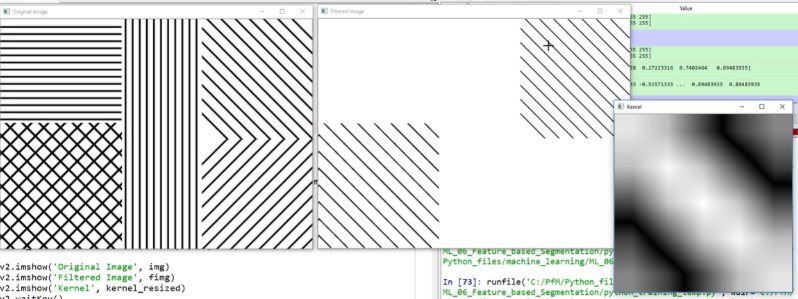

### Useful link: [Gabor Filter Banks Explained — YouTube](https://www.youtube.com/watch?v=QEz4bG9P3Qs)


# b) Implementation

### Implement `extract_gabor_features()`
- **4 frequencies:** `(0.1, 0.2, 0.3, 0.4)` — coarse to fine texture
- **8 orientations:** `(0°, 22.5°, 45°, 67.5°, 90°, 112.5°, 135°, 157.5°)` — captures all structural directions
- Total: 4 × 8 = 32 filters × 2 stats (mean, std) = 64 values → truncated to **32-D feature vector**


In [ ]:
def extract_gabor_features(gray, n_freq=4, n_orient=8):
    features = []
    for freq in np.linspace(0.1, 0.4, n_freq):
        for theta in np.linspace(0, np.pi, n_orient, endpoint=False):
            kernel = cv2.getGaborKernel((21, 21), 4.0, theta, 1.0 / freq, 0.5, 0)
            resp = cv2.filter2D(gray.astype(np.float32), -1, kernel)
            features += [resp.mean(), resp.std()]
    return np.array(features[:32], dtype=np.float32)

figure, axes = plt.subplots(4, 8, figsize=(16, 8))
figure.suptitle("Gabor Filter Bank (4 frequencies x 8 orientations)", fontweight="bold")
for fi, freq in enumerate(np.linspace(0.1, 0.4, 4)):
    for oi, theta in enumerate(np.linspace(0, np.pi, 8, endpoint=False)):
        k = cv2.getGaborKernel((21, 21), 4.0, theta, 1.0 / freq, 0.5, 0)
        axes[fi, oi].imshow(k, cmap="gray"); axes[fi, oi].axis("off")
plt.tight_layout(); plt.show()

## 2.4 LBP (Local Binary Pattern)

# a) Intuition

### What is LBP?

**LBP (Local Binary Pattern)** is a rotation-invariant texture descriptor that encodes the local micro-structure of an image by comparing each pixel to its circular neighborhood.

### How LBP Works
1. **Sample neighbors** on a circle of radius `r` around each pixel (typically `P=24` points at `r=3`)
2. **Threshold**: compare each neighbor's intensity to the center pixel → 1 if neighbor ≥ center, else 0
3. **Encode**: the binary string gives a decimal code for that center pixel
4. **Uniform patterns** (at most 2 bitwise transitions in the binary code) → compact histogram with `P+2` bins
5. **Histogram**: aggregate LBP codes across the whole image → fixed-length feature vector

### Examples:
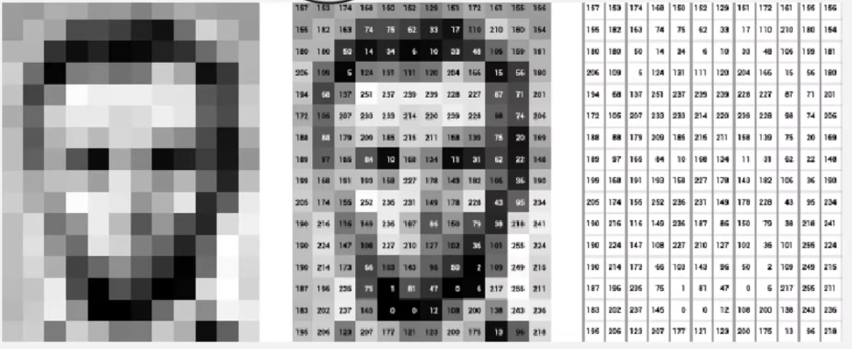

#### Useful links: [LBP Explained — YouTube](https://www.youtube.com/watch?v=h-z9-bMtd7w)

# b) Implementation

### Implement `extract_lbp_features()` — Uniform LBP histogram

Parameters: `radius=3`, `n_points=24` → 26-bin uniform histogram.

In [ ]:
def extract_lbp_features(gray, radius=3, n_points=24, n_bins=26):
    lbp = local_binary_pattern(gray, n_points, radius, method="uniform")
    hist, _ = np.histogram(lbp, bins=n_bins, range=(0, n_bins), density=True)
    return hist.astype(np.float32)

figure, axes = plt.subplots(3, 2, figsize=(7, 9))
figure.suptitle("LBP - Background vs Grape Bunch", fontsize=13, fontweight="bold")
for col, (gray, title) in enumerate(zip(demo_grays, demo_labels)):
    lbp_map = local_binary_pattern(gray, 24, 3, method="uniform")
    hist = extract_lbp_features(gray)
    axes[0, col].imshow(gray, cmap="gray"); axes[0, col].set_title(title, fontweight="bold"); axes[0, col].axis("off")
    axes[1, col].imshow(lbp_map, cmap="gray"); axes[1, col].axis("off")
    axes[2, col].bar(range(26), hist, color="steelblue", edgecolor="black", alpha=0.8)
axes[0, 0].set_ylabel("Grayscale"); axes[1, 0].set_ylabel("LBP Map"); axes[2, 0].set_ylabel("Histogram")
plt.tight_layout(); plt.show()

## 2.5 HOG (Histogram of Oriented Gradients)

## a) Intuition

### What is HOG?

**HOG (Histogram of Oriented Gradients)** captures the distribution of gradient directions in localized image regions. It is the go-to shape descriptor for object recognition in classical computer vision.

### How It Works
1. **Divide** the image into small cells (16×16 pixels here)
2. **Compute gradients** (Sobel-style) at each pixel
3. **Build histograms** of gradient orientations within each cell (9 orientation bins, 0°–180°)
4. **Group cells into blocks** (2×2 cells), normalize each block for illumination invariance
5. **Concatenate** all block histograms → fixed-length feature vector

#### Feature Dimensions
- 128×128 image, 16×16 cell, 2×2 block, 9 orientations:
  - Cells per row/col: 8 × 8 = 64 cells
  - Blocks (with 1-cell stride): 7 × 7 = 49 blocks
  - Descriptors per block: 2×2×9 = 36
  - **Total HOG features: 49 × 36 = 1764**

> **Why 16×16 cells, not the original 8×8:** an ablation on this project's own patches (`background` vs `grape_bunch`) showed 8×8-cell HOG (8100-D, 98% of the whole feature vector) had one of the lowest mutual-information scores of any group (mean MI ≈ 0.017) and was the main reason PCA needed 1900+ of 8284 components to reach 95% variance. Coarsening to 16×16 cells cuts dimensionality ~4.6x *and* raises mean MI to ~0.037 - fewer, more stable gradient histograms generalize better than many noisy fine ones on a 128×128 patch. Zernike moments (formerly Section 2.6) showed the same low-signal pattern (mean MI ≈ 0.016) and, being a whole-image global-shape descriptor, are also a poor conceptual fit for an amorphous, occluded cluster of berries rather than one canonically-shaped object - Section 2.6 now covers what replaced it.

#### Examples:
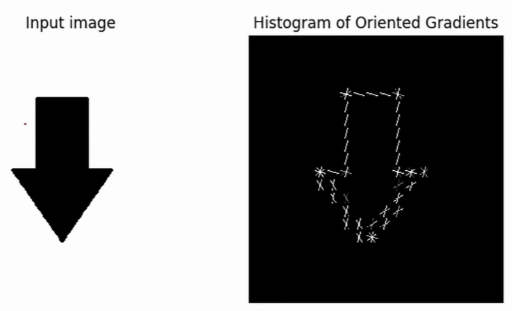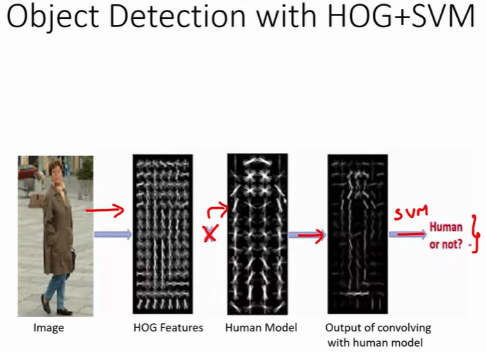

#### Useful link: [HOG Explained - Youtube](https://www.youtube.com/watch?v=28xk5i1_7Zc)


# b) Implementation

In [ ]:
def extract_hog_features(gray, image_size=PATCH_SIZE):
    img = cv2.resize(gray, image_size) if gray.shape[:2] != image_size else gray
    return hog(img, orientations=9, pixels_per_cell=(16, 16),
               cells_per_block=(2, 2), visualize=False, feature_vector=True).astype(np.float32)

figure, axes = plt.subplots(2, 2, figsize=(7, 7))
figure.suptitle("HOG (16x16 cells) - Background vs Grape Bunch", fontsize=13, fontweight="bold")
for col, (gray, title) in enumerate(zip(demo_grays, demo_labels)):
    _, hog_vis = hog(gray, orientations=9, pixels_per_cell=(16, 16),
                      cells_per_block=(2, 2), visualize=True, feature_vector=True)
    axes[0, col].imshow(gray, cmap="gray"); axes[0, col].set_title(title, fontweight="bold"); axes[0, col].axis("off")
    axes[1, col].imshow(hog_vis, cmap="gray"); axes[1, col].axis("off")
axes[0, 0].set_ylabel("Grayscale"); axes[1, 0].set_ylabel("HOG Map")
plt.tight_layout(); plt.show()

print(f"HOG dim: {extract_hog_features(demo_gray_bunch).shape[0]} (was 8100 with 8x8 cells)")

## 2.6 Canny Edge Detection

## a) Intuition

### What is Canny Edge Detection?

**Canny Edge Detection** is a multi-stage algorithm that identifies edges — regions of rapid intensity change — in an image. Developed by John Canny in 1986, it remains one of the most widely used edge detectors due to its accuracy and noise robustness.

### How It Works
1. **Gaussian Smoothing** — Blur the image to suppress noise before edge detection
2. **Gradient Computation** — Apply Sobel filters to measure intensity change in the x and y directions
3. **Non-Maximum Suppression** — Thin candidate edges to a single-pixel width by keeping only local gradient maxima along the gradient direction
4. **Double Thresholding** — Classify gradient pixels as strong edges (above high threshold), weak edges (between thresholds), or non-edges (below low threshold)
5. **Edge Tracking by Hysteresis** — Retain weak edges only if they are connected to a strong edge, producing clean, continuous edge curves

### Useful Links: [Canny Edge Detection Explained - Youtube](https://www.youtube.com/watch?v=sRFM5IEqR2w)

---

## b) Implementation

### Implement `extract_canny_features()` — Edge Statistics

Low threshold `50`, high threshold `150`, Gaussian kernel `5×5` → **5 edge-based scalar features** extracted from the resulting binary edge map.

In [ ]:
def extract_canny_features(gray, low_threshold=50, high_threshold=150):
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, low_threshold, high_threshold)
    h, w = edges.shape
    edge_density = (edges > 0).sum() / (h * w)
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    mean_grad = np.sqrt(gx**2 + gy**2).mean() / 255.0
    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    num_contours = min(len(contours), 500) / 500.0
    mean_len = (np.mean([len(c) for c in contours]) / 100.0) if contours else 0.0
    gx_abs, gy_abs = np.abs(gx), np.abs(gy)
    h_ratio = gy_abs.sum() / (gx_abs.sum() + gy_abs.sum() + 1e-6)
    return np.array([edge_density, mean_grad, num_contours, mean_len, h_ratio], dtype=np.float32)

feat_names = ["Edge\nDensity", "Mean\nGrad", "Contour\nCount", "Contour\nLen", "H/V\nRatio"]
figure, axes = plt.subplots(3, 2, figsize=(7, 9))
figure.suptitle("Canny Edges - Background vs Grape Bunch", fontsize=13, fontweight="bold")
for col, (gray, title) in enumerate(zip(demo_grays, demo_labels)):
    feats = extract_canny_features(gray)
    edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 50, 150)
    axes[0, col].imshow(gray, cmap="gray"); axes[0, col].set_title(title, fontweight="bold"); axes[0, col].axis("off")
    axes[1, col].imshow(edges, cmap="gray"); axes[1, col].axis("off")
    axes[2, col].bar(range(5), feats, color="darkorange", edgecolor="black", alpha=0.8)
    axes[2, col].set_xticks(range(5)); axes[2, col].set_xticklabels(feat_names, fontsize=6)
axes[0, 0].set_ylabel("Grayscale"); axes[1, 0].set_ylabel("Canny Edges"); axes[2, 0].set_ylabel("Features")
plt.tight_layout(); plt.show()

## 2.8 Full Preprocessing Pipeline Visualization

Show a 6-panel comparison for one image from each class: **Original → CLAHE → Gabor → LBP → HOG → Canny**, illustrating how every descriptor in Phase 2 transforms the same image before feature extraction.

In [ ]:
col_titles = ["Original", "CLAHE", "Segmentation Mask", "Gabor (45deg, f=0.2)", "LBP Map", "HOG", "Canny Edges"]
col_names = ["origin", "clahe", "segmask", "gabor", "lbp", "hog", "canny"]

figure, axes = plt.subplots(2, 7, figsize=(26, 7))
figure.suptitle("Full Preprocessing Pipeline - Background vs Grape Bunch", fontsize=14, fontweight="bold")

for row, (patch, title) in enumerate(zip([demo_bg, demo_bunch], demo_labels)):
    original = cv2.cvtColor(patch, cv2.COLOR_BGR2RGB)
    enh_bgr = apply_clahe(patch)
    enh = cv2.cvtColor(enh_bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(enh_bgr, cv2.COLOR_BGR2GRAY)

    seg_mask, _ = segment_grape_regions(patch)

    kernel = cv2.getGaborKernel((21, 21), 4.0, np.pi / 4, 1.0 / 0.2, 0.5, 0)
    gabor_img = np.abs(cv2.filter2D(gray.astype(np.float32), -1, kernel))
    lbp_map = local_binary_pattern(gray, 24, 3, method="uniform")
    _, hog_img = hog(gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    edges_img = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 50, 150)

    imgs = [original, enh, seg_mask, gabor_img, lbp_map, hog_img, edges_img]
    cmaps = [None, None, "gray", "hot", "gray", "gray", "gray"]
    slug = title.lower().replace(" ", "_")
    for col, (img, cmap) in enumerate(zip(imgs, cmaps)):
        axes[row, col].imshow(img, cmap=cmap); axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(col_titles[col], fontsize=10, fontweight="bold")
        fig_exp, ax_exp = plt.subplots(figsize=(3, 3))
        ax_exp.imshow(img, cmap=cmap); ax_exp.axis("off")
        plt.close(fig_exp)
    axes[row, 0].set_ylabel(title, fontsize=9, rotation=90, labelpad=30)

plt.tight_layout(); plt.show()

---
# Phase 3 - Feature Extraction

## 3.1 Combined Feature Vector
### Implement `extract_patch_features()` - Combined Descriptor

In [ ]:
def extract_color_histogram(img_bgr, bins=32):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    hists = [cv2.calcHist([hsv], [c], None, [bins], [0, 256]).flatten() for c in range(3)]
    feature = np.concatenate(hists)
    return (feature / (feature.sum() + 1e-7)).astype(np.float32)

def extract_patch_features(patch_bgr, image_size=PATCH_SIZE):
    """patch_bgr must already be a cropped BGR image; resized to image_size here."""
    bgr = cv2.resize(patch_bgr, image_size) if patch_bgr.shape[:2] != image_size else patch_bgr
    enhanced_bgr = apply_clahe(bgr)
    enhanced_gray = cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2GRAY)

    gabor = extract_gabor_features(enhanced_gray)
    hog_f = extract_hog_features(enhanced_gray, image_size)
    blob = extract_blob_shape_features(enhanced_bgr, image_size)
    haralick = extract_haralick_features(enhanced_gray)
    color = extract_color_histogram(enhanced_bgr)
    lbp = extract_lbp_features(enhanced_gray)
    canny = extract_canny_features(enhanced_gray)

    return np.concatenate([gabor, hog_f, blob, haralick, color, lbp, canny])

test_feat = extract_patch_features(demo_bunch)
print(f"Feature vector dim: {test_feat.shape[0]}")

## 3.2 Build Feature Matrices
### Extract features for all patches and build `X_train`, `X_val`, `X_test`

In [ ]:
def build_feature_matrix(patch_df, desc=""):
    features = []
    for _, row in tqdm(patch_df.iterrows(), total=len(patch_df), desc=desc):
        features.append(extract_patch_features(load_patch(row)))
    return np.array(features, dtype=np.float32), patch_df["label_idx"].values

print("Extracting features...")
X_train, y_train = build_feature_matrix(train_patches, "Train")
X_val, y_val = build_feature_matrix(val_patches, "Val")
X_test, y_test = build_feature_matrix(test_patches, "Test")

print(f"X_train: {X_train.shape}  X_val: {X_val.shape}  X_test: {X_test.shape}")

## 3.3 Feature Vector Inspection - Raw Values & The Scale Problem

In [ ]:
hog_dim_ = extract_hog_features(demo_gray_bunch).shape[0]
blob_dim_ = extract_blob_shape_features(apply_clahe(demo_bunch)).shape[0]
haralick_dim_ = extract_haralick_features(demo_gray_bunch).shape[0]

GROUP_SLICES = {
    "Gabor (32-D)": (0, 32),
    f"HOG ({hog_dim_}-D)": (32, 32 + hog_dim_),
    f"BlobShape ({blob_dim_}-D)": (32 + hog_dim_, 32 + hog_dim_ + blob_dim_),
    f"Haralick ({haralick_dim_}-D)": (32 + hog_dim_ + blob_dim_, 32 + hog_dim_ + blob_dim_ + haralick_dim_),
    "Color HSV (96-D)": (32 + hog_dim_ + blob_dim_ + haralick_dim_, 32 + hog_dim_ + blob_dim_ + haralick_dim_ + 96),
    "LBP (26-D)": (32 + hog_dim_ + blob_dim_ + haralick_dim_ + 96, 32 + hog_dim_ + blob_dim_ + haralick_dim_ + 96 + 26),
    "Canny (5-D)": (32 + hog_dim_ + blob_dim_ + haralick_dim_ + 96 + 26, X_train.shape[1]),
}

group_colors = ["steelblue", "orange", "teal", "darkred", "crimson", "purple", "saddlebrown"]
group_names = list(GROUP_SLICES.keys())
group_meds = [np.median(np.abs(X_train[:, s:e])) for s, e in GROUP_SLICES.values()]
group_maxs = [np.max(np.abs(X_train[:, s:e])) for s, e in GROUP_SLICES.values()]
x = np.arange(len(group_names))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Raw Feature Magnitudes - Why Scaling Is Necessary", fontweight="bold")

axes[0].bar(x, group_maxs, color=group_colors, alpha=0.35, label="Max |value|")
axes[0].bar(x, group_meds, color=group_colors, alpha=0.90, label="Median |value|")
axes[0].set_yscale("log"); axes[0].set_xticks(x); axes[0].set_xticklabels(group_names, fontsize=8)
axes[0].set_ylabel("Magnitude (log scale)"); axes[0].set_title("Global: Median & Max per Group", fontweight="bold")
axes[0].legend(); axes[0].grid(axis="y", alpha=0.3)

bar_w = 0.13
for gi, (name, (s, e)) in enumerate(GROUP_SLICES.items()):
    class_means = [np.mean(np.abs(X_train[y_train == ci, s:e])) for ci in range(NUM_CLASSES)]
    axes[1].bar(np.arange(NUM_CLASSES) + gi * bar_w, class_means, width=bar_w,
                label=name, color=group_colors[gi], alpha=0.85)
axes[1].set_yscale("log")
axes[1].set_xticks(np.arange(NUM_CLASSES) + bar_w * 2.5)
axes[1].set_xticklabels(CLASS_NAMES)
axes[1].set_ylabel("Mean |value| per group (log scale)")
axes[1].set_title("Per-Class: Group Magnitudes", fontweight="bold")
axes[1].legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left"); axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'Group':<22} {'Dims':>6}  {'Min':>10}  {'Max':>10}  {'Mean':>10}  {'Std':>10}")
for name, (s, e) in GROUP_SLICES.items():
    seg = X_train[:, s:e]
    print(f"{name:<22} {e-s:>6}  {seg.min():>10.4f}  {seg.max():>10.4f}  {seg.mean():>10.4f}  {seg.std():>10.4f}")

## 3.4 Feature Scaling

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Scaled - mean: {X_train_scaled.mean():.4f}  std: {X_train_scaled.std():.4f}")
print(f"StandardScaler is fit on the full {X_train.shape[1]}-D matrix - every one of the "
      f"{len(GROUP_SLICES)} groups is scaled, not just the two plotted below (chosen only for readability).")

# Pick the two groups with the most different raw magnitude for the clearest before/after illustration -
# computed from GROUP_SLICES so this stays correct if feature groups change again later.
group_medians = {name: np.median(np.abs(X_train[:, s:e])) for name, (s, e) in GROUP_SLICES.items()}
hi_group = max(group_medians, key=group_medians.get)
lo_group = min(group_medians, key=group_medians.get)
s_hi, e_hi = GROUP_SLICES[hi_group]; s_lo, e_lo = GROUP_SLICES[lo_group]

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_train[:, s_hi:e_hi].ravel(), bins=50, alpha=0.7, label=hi_group, color="steelblue")
axes[0].hist(X_train[:, s_lo:e_lo].ravel(), bins=50, alpha=0.7, label=lo_group, color="orange")
axes[0].set_title("Raw Features"); axes[0].legend()
axes[1].hist(X_train_scaled[:, s_hi:e_hi].ravel(), bins=50, alpha=0.7, label=hi_group, color="steelblue")
axes[1].hist(X_train_scaled[:, s_lo:e_lo].ravel(), bins=50, alpha=0.7, label=lo_group, color="orange")
axes[1].set_title("Scaled Features"); axes[1].legend()
plt.tight_layout(); plt.show()

## 3.5 PCA - Dimensionality Reduction & Visualization

In [ ]:
pca_full = PCA(random_state=SEED)
pca_full.fit(X_train_scaled)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n_95 = np.argmax(cumvar >= 0.95) + 1
n_99 = np.argmax(cumvar >= 0.99) + 1
print(f"95% variance: {n_95} components  99%: {n_99}  Total: {X_train_scaled.shape[1]}")

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(cumvar[:200], linewidth=1.5, color="steelblue")
axes[0].axhline(0.95, color="red", linestyle="--", label="95%")
axes[0].axhline(0.99, color="orange", linestyle="--", label="99%")
axes[0].axvline(n_95, color="red", linestyle=":", alpha=0.6)
axes[0].set_xlabel("Components"); axes[0].set_ylabel("Cumulative Variance")
axes[0].set_title("PCA Scree", fontweight="bold"); axes[0].legend(); axes[0].grid(alpha=0.3)

pca_2d = PCA(n_components=2, random_state=SEED)
X_2d = pca_2d.fit_transform(X_train_scaled)
colors = ["steelblue", "crimson"]
for i, (cls, c) in enumerate(zip(CLASS_NAMES, colors)):
    m = y_train == i
    axes[1].scatter(X_2d[m, 0], X_2d[m, 1], label=cls, alpha=0.5, s=20, color=c)
axes[1].set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)")
axes[1].set_title("2D PCA", fontweight="bold")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

pca_95 = PCA(n_components=n_95, random_state=SEED)
X_train_pca = pca_95.fit_transform(X_train_scaled)
X_val_pca = pca_95.transform(X_val_scaled)
X_test_pca = pca_95.transform(X_test_scaled)
print(f"PCA shapes - train: {X_train_pca.shape}, val: {X_val_pca.shape}, test: {X_test_pca.shape}")

## 3.6 Feature Group Importance Preview
### Compute mutual information per feature group

In [ ]:
feature_groups = GROUP_SLICES

print("Computing mutual information scores...")
mi_scores = mutual_info_classif(X_train_scaled, y_train, random_state=SEED)

group_mi = {name: mi_scores[s:e].mean() for name, (s, e) in feature_groups.items()}
group_df = pd.DataFrame(group_mi.items(), columns=["Feature Group", "Mean MI Score"])
group_df = group_df.sort_values("Mean MI Score", ascending=True)

plt.figure(figsize=(9, 5))
bars = plt.barh(group_df["Feature Group"], group_df["Mean MI Score"], color="steelblue", edgecolor="black", alpha=0.8)
plt.xlabel("Average Mutual Information Score")
plt.title("Feature Group Discriminativeness", fontweight="bold")
for bar, val in zip(bars, group_df["Mean MI Score"]):
    plt.text(val + 0.0003, bar.get_y() + bar.get_height()/2, f"{val:.4f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

for _, row in group_df.sort_values("Mean MI Score", ascending=False).iterrows():
    print(f"  {row['Feature Group']:25s}: {row['Mean MI Score']:.4f}")

---
# Phase 4 - Model Training

## 4.1 Model Configuration & Training Helpers
### Define evaluation helper and train all models

In [ ]:
def evaluate_model(model, X, y_true, split_name=""):
    preds = model.predict(X)
    acc = accuracy_score(y_true, preds)
    try:
        proba = model.predict_proba(X)
    except AttributeError:
        proba = None
    report = classification_report(y_true, preds, target_names=CLASS_NAMES, output_dict=True)
    if split_name:
        print(f"  [{split_name}] Acc: {acc*100:.2f}%  F1: {report['macro avg']['f1-score']*100:.2f}%")
    return acc, preds, proba, report


class HeterogeneousEnsemble:
    """Soft-votes across already-trained models of different families instead of bagging one
    algorithm under different seeds - SVM, XGBoost, and Random Forest make different mistakes,
    so combining them should generalize better than 5 seeds of the same XGBoost config.
    Takes already-scaled features; routes the SVM member through `pca` internally since it
    needs a different input space than the tree models. Defined here (Phase 4.1, not 4.2) so it
    always exists before Phase 4.3's load-from-disk path, which may run without Phase 4.2."""
    def __init__(self, models, pca):
        self.models = models  # dict: name -> fitted model
        self.pca = pca

    def predict_proba(self, X_scaled):
        probas = []
        for name, model in self.models.items():
            X_in = self.pca.transform(X_scaled) if name == "SVM" else X_scaled
            probas.append(model.predict_proba(X_in))
        return np.mean(probas, axis=0)

    def predict(self, X_scaled):
        return np.argmax(self.predict_proba(X_scaled), axis=1)


trained_models = {}
val_results = {}
print("Helpers ready.")

## 4.2 Train All Models
### Train SVM-equivalent (Nystroem RBF approximation + SGD) with GridSearchCV (skip this if we have saved model)

GPU note: no GPU-accelerated kernel SVM is available for Python 3.14 (RAPIDS cuML doesn't support it yet), so instead of `SVC(kernel="rbf")` this approximates the same RBF decision boundary with a `Nystroem` feature map + `SGDClassifier` - linear cost in the number of rows instead of the kernel SVM's quadratic-to-cubic cost, measured to be ~20x+ faster at this project's training-set size.

In [ ]:
# GPU/speed note: sklearn's kernel SVC has no GPU path, and RAPIDS cuML (the usual GPU drop-in
# for SVC) doesn't support Python 3.14 yet. Replacing the RBF-kernel SVC with a Nystroem RBF
# feature map + SGDClassifier(loss="log_loss") - the standard sklearn pattern for scaling kernel
# methods to linear-in-n cost instead of RBF-SVC's O(n^2)-O(n^3). Measured directly on this
# project's scale (488-D PCA space, 12k rows): ~0.2s per fit vs several seconds-to-minutes per
# RBF-SVC fit at the same size, so the grid search no longer needs a subsample workaround.
def make_svm_pipeline(gamma, n_components, alpha):
    return make_pipeline(
        Nystroem(gamma=gamma, n_components=n_components, random_state=SEED),
        SGDClassifier(loss="log_loss", alpha=alpha, random_state=SEED),
    )

param_grid_svm = {
    "nystroem__gamma": [0.001, 0.01, 0.05],
    "nystroem__n_components": [200, 400],
    "sgdclassifier__alpha": [1e-4, 1e-3],
}
svm_base = make_svm_pipeline(gamma=0.01, n_components=200, alpha=1e-4)
cv_svm = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

print(f"Training SVM (Nystroem + SGD) - 12 combos, {CV_FOLDS}-fold CV, input: {X_train_pca.shape}")
t0 = time.time()
svm_grid = GridSearchCV(svm_base, param_grid_svm, cv=cv_svm, scoring="f1", n_jobs=-1, refit=False, verbose=1)
# threading backend, not the joblib default (loky/process-based): this Pipeline(Nystroem, SGD)
# combo triggers a benign-but-noisy sklearn.utils.parallel "delayed should be used with Parallel"
# UserWarning once per worker process - the main process's warnings.filterwarnings("ignore") above
# doesn't reach separate worker processes here. Threading keeps every fit in this process instead,
# where the suppression already applies; measured cost is small since each fit is already ~0.2s.
with joblib.parallel_backend("threading"):
    svm_grid.fit(X_train_pca, y_train)
print(f"Best params: {svm_grid.best_params_}  CV F1: {svm_grid.best_score_*100:.2f}%  "
      f"({time.time()-t0:.1f}s search)")

t0 = time.time()
best_svm = make_svm_pipeline(
    gamma=svm_grid.best_params_["nystroem__gamma"],
    n_components=svm_grid.best_params_["nystroem__n_components"],
    alpha=svm_grid.best_params_["sgdclassifier__alpha"],
)
best_svm.fit(X_train_pca, y_train)
t_svm = time.time() - t0
print(f"Refit on full {X_train_pca.shape[0]}-row training set ({t_svm:.1f}s)")

svm_val_acc, svm_val_preds, svm_val_proba, svm_val_report = evaluate_model(best_svm, X_val_pca, y_val, "SVM Val")
trained_models["SVM"] = best_svm
val_results["SVM"] = {"accuracy": svm_val_acc, "preds": svm_val_preds, "proba": svm_val_proba,
                       "report": svm_val_report, "best_params": svm_grid.best_params_, "train_time": t_svm}


### Train XGBoost (skip this if we have saved model)

In [ ]:
print(f"Training XGBoost - input: X_train_scaled {X_train_scaled.shape}")
t0 = time.time()
xgb_model = xgb.XGBClassifier(
    n_estimators=500, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    objective="binary:logistic", eval_metric="logloss",
    early_stopping_rounds=30, random_state=SEED, verbosity=0,
    tree_method="hist", device="cuda",  # GPU: this xgboost build has CUDA support (~26x faster measured)
)
xgb_model.fit(X_train_scaled, y_train, eval_set=[(X_val_scaled, y_val)], verbose=False)
t_xgb = time.time() - t0

print(f"Best iter: {xgb_model.best_iteration}  val logloss: {xgb_model.best_score:.4f} ({t_xgb:.1f}s)")

xgb_val_acc, xgb_val_preds, xgb_val_proba, xgb_val_report = evaluate_model(xgb_model, X_val_scaled, y_val, "XGBoost Val")
trained_models["XGBoost"] = xgb_model
val_results["XGBoost"] = {"accuracy": xgb_val_acc, "preds": xgb_val_preds, "proba": xgb_val_proba,
                           "report": xgb_val_report, "best_iter": xgb_model.best_iteration, "train_time": t_xgb}

### Train Random Forest (skip this if we have saved model)

In [ ]:
# GPU/speed note: sklearn's RandomForestClassifier has no GPU path, and RAPIDS cuML's GPU
# RandomForestClassifier doesn't support Python 3.14 yet. xgboost's own GPU "random forest" mode
# (XGBRFClassifier) was tried directly at this project's feature scale (~20k rows x ~1900-D full
# scaled features) and reliably ran out of GPU memory even at the smallest grid corner (200 trees,
# depth 20) - it builds every tree in the round in parallel on the GPU at once, unlike sequential
# boosting, so memory doesn't stay bounded the way XGBoost's boosted mode does. It's also
# deprecated in this xgboost version. So Random Forest stays on CPU, sped up the same way as the
# SVM cell: grid-search on a stratified subsample, then refit only the winning combo on full data.
param_grid_rf = {
    "n_estimators": [200, 500],
    "max_depth": [20, 40],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt"],
}
# n_jobs=1 here, not -1: this RandomForestClassifier is the estimator INSIDE
# GridSearchCV(n_jobs=-1) below - nesting n_jobs=-1 inside n_jobs=-1 oversubscribes the
# CPU (far more processes than cores) and reliably triggers a benign but noisy
# sklearn.utils.parallel UserWarning. Measured directly: single-inner is also faster
# (3.3s vs 5.1s on an equivalent grid) since the 24 outer fits alone already saturate
# every core. The standalone refit below keeps n_jobs=-1 since it isn't nested.
rf_base = RandomForestClassifier(random_state=SEED, n_jobs=1)
cv_rf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

RF_SEARCH_SUBSAMPLE = min(12000, len(X_train_scaled))
if RF_SEARCH_SUBSAMPLE < len(X_train_scaled):
    X_rf_search, _, y_rf_search, _ = train_test_split(
        X_train_scaled, y_train, train_size=RF_SEARCH_SUBSAMPLE, stratify=y_train, random_state=SEED
    )
else:
    X_rf_search, y_rf_search = X_train_scaled, y_train

print(f"Training Random Forest - 8 combos, {CV_FOLDS}-fold CV, search on {X_rf_search.shape[0]} of "
      f"{X_train_scaled.shape[0]} train rows")
t0 = time.time()
rf_grid = GridSearchCV(rf_base, param_grid_rf, cv=cv_rf, scoring="f1", n_jobs=-1, refit=False, verbose=1)
rf_grid.fit(X_rf_search, y_rf_search)
print(f"Best params: {rf_grid.best_params_}  CV F1: {rf_grid.best_score_*100:.2f}%  ({time.time()-t0:.1f}s search)")

t0 = time.time()
best_rf = RandomForestClassifier(random_state=SEED, n_jobs=-1, **rf_grid.best_params_)
best_rf.fit(X_train_scaled, y_train)
t_rf = time.time() - t0
print(f"Refit on full {X_train_scaled.shape[0]}-row training set ({t_rf:.1f}s)")

rf_val_acc, rf_val_preds, rf_val_proba, rf_val_report = evaluate_model(best_rf, X_val_scaled, y_val, "RF Val")
trained_models["Random Forest"] = best_rf
val_results["Random Forest"] = {"accuracy": rf_val_acc, "preds": rf_val_preds, "proba": rf_val_proba,
                                 "report": rf_val_report, "best_params": rf_grid.best_params_, "train_time": t_rf}


### Build Ensemble Model - soft vote of SVM + XGBoost + Random Forest (skip this if we have saved model)

In [ ]:
print("Building Ensemble: soft vote across the already-trained SVM + XGBoost + Random Forest...")
t0 = time.time()
ensemble_model = HeterogeneousEnsemble(
    models={"SVM": best_svm, "XGBoost": xgb_model, "Random Forest": best_rf},
    pca=pca_95,
)
t_ensemble = time.time() - t0  # ~0s: no new training, just combines already-trained models

ensemble_val_proba = ensemble_model.predict_proba(X_val_scaled)
ensemble_val_preds = np.argmax(ensemble_val_proba, axis=1)
ensemble_val_acc = accuracy_score(y_val, ensemble_val_preds)
ensemble_val_report = classification_report(y_val, ensemble_val_preds, target_names=CLASS_NAMES, output_dict=True)
auc_pr = average_precision_score(y_val, ensemble_val_proba[:, 1])

print(f"Ensemble complete: SVM + XGBoost + Random Forest soft vote ({t_ensemble:.2f}s)")
print(f"  [Ensemble Val] Acc: {ensemble_val_acc*100:.2f}%  "
      f"F1: {ensemble_val_report['macro avg']['f1-score']*100:.2f}%  AUC-PR: {auc_pr:.4f}")

trained_models["Ensemble"] = ensemble_model
val_results["Ensemble"] = {"accuracy": ensemble_val_acc, "preds": ensemble_val_preds, "proba": ensemble_val_proba,
                            "report": ensemble_val_report, "auc_pr": auc_pr, "train_time": t_ensemble}

## 4.3 Save & Load Trained Models

In [ ]:
joblib.dump(best_svm, MODELS_DIR / "svm.joblib")
joblib.dump(xgb_model, MODELS_DIR / "xgboost.joblib")
joblib.dump(best_rf, MODELS_DIR / "random_forest.joblib")
joblib.dump(ensemble_model, MODELS_DIR / "ensemble.joblib")
joblib.dump(scaler, MODELS_DIR / "scaler.joblib")
joblib.dump(pca_95, MODELS_DIR / "pca.joblib")

np.save(MODELS_DIR / "X_train.npy", X_train)
np.save(MODELS_DIR / "X_val.npy", X_val)
np.save(MODELS_DIR / "X_test.npy", X_test)
np.save(MODELS_DIR / "y_train.npy", y_train)
np.save(MODELS_DIR / "y_val.npy", y_val)
np.save(MODELS_DIR / "y_test.npy", y_test)

meta = {
    "svm_best_params": svm_grid.best_params_,
    "xgb_best_iteration": int(xgb_model.best_iteration),
    "rf_best_params": rf_grid.best_params_,
    "n_95": int(n_95),
}
(MODELS_DIR / "meta.json").write_text(json.dumps(meta, indent=2))

print(f"All models saved to '{MODELS_DIR}/'")
for f in sorted(MODELS_DIR.iterdir()):
    if f.is_file():
        print(f"  {f.name:<30s}  {f.stat().st_size / 1e6:.2f} MB")

In [ ]:
# Run this cell to restore all saved models and skip Phase 4 training.
# Requires the Save cell above to have been executed at least once.
_files = ["svm.joblib", "xgboost.joblib", "random_forest.joblib", "ensemble.joblib",
          "scaler.joblib", "pca.joblib", "meta.json",
          "X_train.npy", "X_val.npy", "X_test.npy", "y_train.npy", "y_val.npy", "y_test.npy"]

if all((MODELS_DIR / f).exists() for f in _files):
    print("Loading pre-trained models from disk...")
    best_svm = joblib.load(MODELS_DIR / "svm.joblib")
    xgb_model = joblib.load(MODELS_DIR / "xgboost.joblib")
    best_rf = joblib.load(MODELS_DIR / "random_forest.joblib")
    ensemble_model = joblib.load(MODELS_DIR / "ensemble.joblib")
    scaler = joblib.load(MODELS_DIR / "scaler.joblib")
    pca_95 = joblib.load(MODELS_DIR / "pca.joblib")

    X_train = np.load(MODELS_DIR / "X_train.npy"); X_val = np.load(MODELS_DIR / "X_val.npy"); X_test = np.load(MODELS_DIR / "X_test.npy")
    y_train = np.load(MODELS_DIR / "y_train.npy"); y_val = np.load(MODELS_DIR / "y_val.npy"); y_test = np.load(MODELS_DIR / "y_test.npy")

    _meta = json.loads((MODELS_DIR / "meta.json").read_text())
    n_95 = _meta["n_95"]

    class _GS:
        def __init__(self, p): self.best_params_ = p
    svm_grid = _GS(_meta["svm_best_params"])
    rf_grid = _GS(_meta["rf_best_params"])

    X_train_scaled = scaler.transform(X_train); X_val_scaled = scaler.transform(X_val); X_test_scaled = scaler.transform(X_test)
    X_train_pca = pca_95.transform(X_train_scaled); X_val_pca = pca_95.transform(X_val_scaled); X_test_pca = pca_95.transform(X_test_scaled)

    trained_models, val_results = {}, {}
    for name, (mdl, Xv) in [("SVM", (best_svm, X_val_pca)), ("XGBoost", (xgb_model, X_val_scaled)),
                             ("Random Forest", (best_rf, X_val_scaled))]:
        acc, preds, proba, report = evaluate_model(mdl, Xv, y_val, split_name=f"{name} Val")
        trained_models[name] = mdl
        val_results[name] = {"accuracy": acc, "preds": preds, "proba": proba, "report": report, "train_time": 0,
                              "best_params": (svm_grid.best_params_ if name == "SVM" else rf_grid.best_params_)}

    ens_proba = ensemble_model.predict_proba(X_val_scaled)
    ens_preds = np.argmax(ens_proba, axis=1)
    ens_acc = accuracy_score(y_val, ens_preds)
    ens_report = classification_report(y_val, ens_preds, target_names=CLASS_NAMES, output_dict=True)
    trained_models["Ensemble"] = ensemble_model
    val_results["Ensemble"] = {"accuracy": ens_acc, "preds": ens_preds, "proba": ens_proba, "report": ens_report, "train_time": 0}
    print(f"  [Ensemble Val] Acc: {ens_acc*100:.2f}%  F1: {ens_report['macro avg']['f1-score']*100:.2f}%")
    print(f"Loaded {len(trained_models)} models. Jump directly to Phase 5.")
else:
    print("No saved models found - run the Phase 4 training cells first.")

## 4.4 Validation Performance Summary

In [ ]:
print(f"{'Model':<20} {'Val Acc':>9} {'F1':>7} {'Prec':>7} {'Rec':>7} {'Time':>7}")
print("-" * 60)
summary_rows = []
for name, res in val_results.items():
    acc = res["accuracy"]; rep = res["report"]
    print(f"{name:<20} {acc*100:>8.2f}%  {rep['macro avg']['f1-score']*100:>6.2f}%  "
          f"{rep['macro avg']['precision']*100:>6.2f}%  {rep['macro avg']['recall']*100:>6.2f}%  {res['train_time']:>6.1f}s")
    summary_rows.append({"Model": name, "Val Acc (%)": round(acc*100, 2), "Macro F1 (%)": round(rep["macro avg"]["f1-score"]*100, 2)})

best_model_name = max(val_results, key=lambda m: val_results[m]["accuracy"])
print(f"\nBest: {best_model_name} ({val_results[best_model_name]['accuracy']*100:.2f}%)")
summary_df = pd.DataFrame(summary_rows)

model_names = list(val_results.keys())
accs = [val_results[m]["accuracy"]*100 for m in model_names]
f1s = [val_results[m]["report"]["macro avg"]["f1-score"]*100 for m in model_names]
colors = ["steelblue", "darkorange", "forestgreen", "purple"]
x = np.arange(len(model_names))

figure, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, vals, title, ylabel in zip(axes, [accs, f1s], ["Val Accuracy", "Val Macro-F1"], ["Accuracy (%)", "Macro F1 (%)"]):
    ax.bar(x, vals, color=colors[:len(model_names)], edgecolor="black", alpha=0.85)
    ax.set_xticks(x); ax.set_xticklabels(model_names, fontsize=11)
    ax.set_ylabel(ylabel); ax.set_title(title, fontweight="bold"); ax.set_ylim(0, 110)
    for xi, v in zip(x, vals):
        ax.text(xi, v+1, f"{v:.1f}%", ha="center", fontsize=10, fontweight="bold")
    ax.axhline(50, color="gray", linestyle="--", alpha=0.5, label="Chance")
    ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.suptitle("Phase 4 - Validation Performance", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

## 4.5 Learning Curves Analysis
### How do models scale with training data? - Bias-variance diagnosis

In [ ]:
lc_configs = {
    "SVM": (make_svm_pipeline(
                gamma=svm_grid.best_params_["nystroem__gamma"],
                n_components=svm_grid.best_params_["nystroem__n_components"],
                alpha=svm_grid.best_params_["sgdclassifier__alpha"],
            ),
            X_train_pca, y_train),
    # n_jobs=1: nested inside learning_curve's own n_jobs=-1 below (see the 4.4 RF cell for why).
    "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=1, **val_results["Random Forest"]["best_params"]),
                       X_train_scaled, y_train),
    "XGBoost": (xgb.XGBClassifier(n_estimators=min(xgb_model.best_iteration + 1, 100), max_depth=4, learning_rate=0.05,
                                   subsample=0.8, colsample_bytree=0.8, tree_method="hist", device="cuda",
                                   objective="binary:logistic", eval_metric="logloss",
                                   random_state=SEED, verbosity=0),
                X_train_pca, y_train),
    "Ensemble (proxy)": (xgb.XGBClassifier(n_estimators=50, max_depth=4, learning_rate=0.05,
                                            subsample=0.8, colsample_bytree=0.7, min_child_weight=5,
                                            gamma=0.1, reg_alpha=0.1, reg_lambda=2.0, tree_method="hist", device="cuda",
                                            objective="binary:logistic", eval_metric="logloss",
                                            random_state=SEED, verbosity=0),
                          X_train_pca, y_train),
}

cv_lc = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
sizes = np.linspace(0.1, 1.0, 6)

if os.path.exists(LC_CACHE_DIR):
    print(f"[Cache] Loading learning curve data from {LC_CACHE_DIR} - skipping recomputation.")
    with open(LC_CACHE_DIR, "rb") as f:
        lc_data = pickle.load(f)
else:
    lc_data = {}
    for name, (est, Xlc, ylc) in lc_configs.items():
        # GPU-backed XGBoost configs run serially (n_jobs=1): joblib's process-level parallelism
        # would otherwise point several worker processes at the same GPU at once, which risks
        # CUDA out-of-memory contention rather than any speedup. SVM (Nystroem + SGD) runs on the
        # threading backend instead of the default loky/process backend - process workers here
        # trigger a benign but noisy sklearn.utils.parallel UserWarning (see the 4.2 SVM cell).
        n_jobs = 1 if name in ("XGBoost", "Ensemble (proxy)") else -1
        backend = "threading" if name == "SVM" else "loky"
        print(f"Learning curve - {name}...")
        with joblib.parallel_backend(backend):
            sz, tr, val = learning_curve(est, Xlc, ylc, train_sizes=sizes, cv=cv_lc, scoring="accuracy",
                                          n_jobs=n_jobs, shuffle=True, random_state=SEED)
        lc_data[name] = (sz, tr, val)
    with open(LC_CACHE_DIR, "wb") as f:
        pickle.dump(lc_data, f)
    print(f"[Cache] Saved to {LC_CACHE_DIR}")

n_lc = len(lc_data)
figure, axes = plt.subplots(1, n_lc, figsize=(5*n_lc, 5), sharey=True)
for ax, (name, (sz, tr, val)) in zip(axes, lc_data.items()):
    trm, trs = tr.mean(1)*100, tr.std(1)*100
    vlm, vls = val.mean(1)*100, val.std(1)*100
    ax.plot(sz, trm, "o-", color="steelblue", label="Train", lw=2)
    ax.fill_between(sz, trm-trs, trm+trs, alpha=0.15, color="steelblue")
    ax.plot(sz, vlm, "s--", color="darkorange", label="CV Val", lw=2)
    ax.fill_between(sz, vlm-vls, vlm+vls, alpha=0.15, color="darkorange")
    ax.set_title(name, fontweight="bold"); ax.set_xlabel("Training Size")
    ax.set_ylabel("Accuracy (%)" if ax is axes[0] else "")
    ax.set_ylim(0, 110); ax.axhline(50, color="gray", linestyle=":", alpha=0.6)
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    ax.text(0.05, 0.05, f"Gap: {trm[-1]-vlm[-1]:.1f}%", transform=ax.transAxes, fontsize=9, color="red", alpha=0.8)
plt.suptitle("Learning Curves", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

## 4.6 Cross-Validation Comparison

In [ ]:
class _FrozenPCA:
    """Shields a fitted PCA from sklearn's clone() - clone() resets any constructor param that
    itself exposes get_params(), which would silently discard pca_95's fitted state on every
    CV fold. Wrapping it in a plain object (no get_params) makes clone() deepcopy it instead,
    which preserves the fit."""
    def __init__(self, pca):
        self.pca = pca
    def transform(self, X):
        return self.pca.transform(X)


class HeterogeneousEnsembleWrapper(BaseEstimator, ClassifierMixin):
    """Sklearn-compatible (clonable) wrapper matching the deployed HeterogeneousEnsemble:
    fits a fresh SVM + XGBoost + Random Forest per call and soft-votes their predictions.
    Expects already-scaled (not PCA-reduced) X; routes its own SVM member through `pca`
    internally, same as HeterogeneousEnsemble in Phase 4.1/4.2/6. Inherits BaseEstimator/
    ClassifierMixin (rather than hand-rolling get_params/set_params) because sklearn >=1.6's
    cross_val_score requires `__sklearn_tags__`, which only BaseEstimator provides."""
    def __init__(self, pca, svm_params, rf_params, xgb_params):
        self.pca = pca
        self.svm_params = svm_params
        self.rf_params = rf_params
        self.xgb_params = xgb_params

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        X_pca = self.pca.transform(X)
        self.svm_ = make_svm_pipeline(**self.svm_params).fit(X_pca, y)
        self.rf_ = RandomForestClassifier(random_state=SEED, n_jobs=-1, **self.rf_params).fit(X, y)
        self.xgb_ = xgb.XGBClassifier(**self.xgb_params).fit(X, y, verbose=False)
        return self

    def predict_proba(self, X):
        probas = [self.svm_.predict_proba(self.pca.transform(X)), self.rf_.predict_proba(X), self.xgb_.predict_proba(X)]
        return np.mean(probas, axis=0)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

X_trainval_scaled = np.vstack([X_train_scaled, X_val_scaled])
y_trainval = np.concatenate([y_train, y_val])
X_trainval_pca = pca_95.transform(X_trainval_scaled)

if os.path.exists(CV_CACHE_DIR):
    print(f"[Cache] Loading CV results from {CV_CACHE_DIR} - skipping recomputation.")
    with open(CV_CACHE_DIR, "rb") as f:
        cache = pickle.load(f)
    cv_results = cache["cv_results"]; cv_summary = cache["cv_summary"]
    print(f"{CV_FOLDS}-fold CV on train+val ({len(y_trainval)} samples) [from cache]")
    for name, scores in cv_results.items():
        folds = "  ".join([f"{s*100:.1f}%" for s in scores])
        print(f"{name:<20} {scores.mean()*100:.2f}% +/- {scores.std()*100:.2f}%  : {folds}")
else:
    cv_compare = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    _svm_best = {
        "gamma": val_results["SVM"]["best_params"]["nystroem__gamma"],
        "n_components": val_results["SVM"]["best_params"]["nystroem__n_components"],
        "alpha": val_results["SVM"]["best_params"]["sgdclassifier__alpha"],
    }
    cv_estimators = {
        "SVM": (make_svm_pipeline(**_svm_best), X_trainval_pca),
        # n_jobs=1: nested inside cross_val_score's own n_jobs=-1 below (see the 4.4 RF cell for why).
        "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=1, **val_results["Random Forest"]["best_params"]), X_trainval_scaled),
        "XGBoost": (xgb.XGBClassifier(n_estimators=xgb_model.best_iteration+1, max_depth=4, learning_rate=0.05,
                                       subsample=0.8, colsample_bytree=0.8, tree_method="hist", device="cuda",
                                       objective="binary:logistic", eval_metric="logloss",
                                       random_state=SEED, verbosity=0), X_trainval_scaled),
        "Ensemble": (HeterogeneousEnsembleWrapper(
            pca=_FrozenPCA(pca_95),
            svm_params=_svm_best,
            rf_params=val_results["Random Forest"]["best_params"],
            xgb_params=dict(n_estimators=xgb_model.best_iteration + 1, max_depth=4, learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8, tree_method="hist", device="cuda",
                             objective="binary:logistic", eval_metric="logloss",
                             random_state=SEED, verbosity=0),
        ), X_trainval_scaled),
    }
    cv_results = {}
    print(f"{CV_FOLDS}-fold CV on train+val ({len(y_trainval)} samples)")
    for name, (est, Xcv) in cv_estimators.items():
        # GPU-backed XGBoost (and Ensemble, which fits an XGBoost member) run serially to avoid
        # several joblib worker processes contending for the same GPU at once. SVM (Nystroem + SGD)
        # runs on the threading backend instead of loky/process - see the 4.2 SVM cell for why.
        n_jobs = 1 if name in ("Ensemble", "XGBoost") else -1
        backend = "threading" if name == "SVM" else "loky"
        with joblib.parallel_backend(backend):
            scores = cross_val_score(est, Xcv, y_trainval, cv=cv_compare, scoring="accuracy", n_jobs=n_jobs)
        cv_results[name] = scores
        folds = "  ".join([f"{s*100:.1f}%" for s in scores])
        print(f"{name:<20} {scores.mean()*100:.2f}% +/- {scores.std()*100:.2f}%  : {folds}")
    cv_summary = {m: {"mean": float(s.mean()), "std": float(s.std()), "folds": s.tolist()} for m, s in cv_results.items()}
    with open(CV_CACHE_DIR, "wb") as f:
        pickle.dump({"cv_results": cv_results, "cv_summary": cv_summary}, f)
    print(f"[Cache] Saved to {CV_CACHE_DIR}")

_colors = ["steelblue", "darkorange", "forestgreen", "purple"]
figure, ax = plt.subplots(figsize=(10, 5))
bplot = ax.boxplot([cv_results[m]*100 for m in cv_results], patch_artist=True, widths=0.5)
for patch, c in zip(bplot["boxes"], _colors):
    patch.set_facecolor(c); patch.set_alpha(0.75)
for i, scores in enumerate([cv_results[m]*100 for m in cv_results], start=1):
    ax.scatter([i]*len(scores), scores, color="black", s=30, zorder=5, alpha=0.7)
ax.set_xticks(range(1, len(cv_results)+1)); ax.set_xticklabels(list(cv_results.keys()), fontsize=12)
ax.set_ylabel("Accuracy (%)"); ax.set_title(f"{CV_FOLDS}-Fold CV", fontweight="bold")
ax.axhline(50, color="gray", linestyle="--", alpha=0.5)
ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()
print("Phase 4 complete.")

---
# Phase 5 - Patch Classifier Evaluation

## 5.1 Test Set Performance
### Evaluate all models on held-out test set

In [ ]:
model_test_configs = {
    "SVM": (trained_models["SVM"], X_test_pca),
    "XGBoost": (trained_models["XGBoost"], X_test_scaled),
    "Random Forest": (trained_models["Random Forest"], X_test_scaled),
}

test_results = {}
print("Test Set Evaluation")
for name, (model, Xte) in model_test_configs.items():
    acc, preds, proba, report = evaluate_model(model, Xte, y_test)
    roc_auc = roc_auc_score(y_test, proba[:, 1]) if proba is not None else None
    test_results[name] = {"accuracy": acc, "roc_auc": roc_auc, "preds": preds.tolist(),
                           "proba": proba.tolist() if proba is not None else None, "report": report}
    print(f"\n{name}")
    print(f"  Accuracy: {acc*100:.2f}%" + (f"  ROC-AUC: {roc_auc:.4f}" if roc_auc else ""))
    print(f"  Macro F1: {report['macro avg']['f1-score']*100:.2f}%  Prec: {report['macro avg']['precision']*100:.2f}%")

ens_proba_test = trained_models["Ensemble"].predict_proba(X_test_scaled)
ens_preds_test = np.argmax(ens_proba_test, axis=1)
ens_acc_test = accuracy_score(y_test, ens_preds_test)
ens_roc_auc_test = roc_auc_score(y_test, ens_proba_test[:, 1])
ens_report_test = classification_report(y_test, ens_preds_test, target_names=CLASS_NAMES, output_dict=True)
test_results["Ensemble"] = {"accuracy": ens_acc_test, "roc_auc": ens_roc_auc_test, "preds": ens_preds_test.tolist(),
                             "proba": ens_proba_test.tolist(), "report": ens_report_test}
print(f"\nEnsemble")
print(f"Accuracy: {ens_acc_test*100:.2f}%  ROC-AUC: {ens_roc_auc_test:.4f}")
print(f"Macro F1: {ens_report_test['macro avg']['f1-score']*100:.2f}%  Prec: {ens_report_test['macro avg']['precision']*100:.2f}%")

test_preds = {m: np.array(r["preds"]) for m, r in test_results.items()}
test_probas = {m: np.array(r["proba"]) for m, r in test_results.items() if r["proba"]}

## 5.2 Confusion Matrices & Classification Report

In [ ]:
best_model_name = max(test_results, key=lambda m: test_results[m]["accuracy"])
print(f"Best: {best_model_name} ({test_results[best_model_name]['accuracy']*100:.2f}%)\n")
print(classification_report(y_test, test_preds[best_model_name], target_names=CLASS_NAMES))

n_m = len(test_preds)
figure, axes = plt.subplots(1, n_m, figsize=(4.5*n_m, 4.5))
if n_m == 1: axes = [axes]
figure.suptitle("Normalized Confusion Matrices (Test Set)", fontsize=14, fontweight="bold")
for ax, m in zip(axes, test_preds):
    cm = confusion_matrix(y_test, test_preds[m], normalize="true")
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right", fontsize=9)
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES, fontsize=9)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"{m}\n(Acc={test_results[m]['accuracy']*100:.1f}%)", fontweight="bold")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            color = "white" if cm[i, j] > 0.6 else "black"
            ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center", fontsize=9, color=color, fontweight="bold")
plt.tight_layout(); plt.show()

---
# Phase 6 - Full-Image Detection & Counting Pipeline

Phases 1-5 only prove the classifier can tell a 128x128 grape-bunch crop from a background crop apart - necessary, but not the deliverable. The deliverable is: given one full field photo, find every bunch and report a count. This phase wires the Phase 2.2 segmentation proposals and the Phase 4 classifier together, adds non-max suppression to collapse duplicate/overlapping detections down to one box per real bunch, and validates the whole thing against ground-truth bunch counts.

## 6.1 Candidate Scoring - Classify Every Proposed Region

In [ ]:
def model_predict_proba_bunch(model_name, X_scaled):
    """Return P(grape_bunch) for a batch of already-scaled feature vectors, for any trained model.
    HeterogeneousEnsemble (the "Ensemble" model) already routes its own SVM member through PCA
    internally, so it - like every other model here - just takes X_scaled directly."""
    model = trained_models[model_name]
    if model_name == "SVM":
        X_in = pca_95.transform(X_scaled)
        return model.predict_proba(X_in)[:, 1]
    return model.predict_proba(X_scaled)[:, 1]


def score_candidates(img_bgr, boxes, model_name):
    if not boxes:
        return np.array([])
    feats = []
    for (x1, y1, x2, y2) in boxes:
        crop = img_bgr[y1:y2, x1:x2]
        if crop.size == 0:
            feats.append(np.zeros(X_train.shape[1], dtype=np.float32))
            continue
        feats.append(extract_patch_features(cv2.resize(crop, PATCH_SIZE)))
    X = scaler.transform(np.array(feats, dtype=np.float32))
    return model_predict_proba_bunch(model_name, X)

## 6.2 Non-Maximum Suppression

In [ ]:
def _containment(a, b):
    """Fraction of box b's area that lies inside box a."""
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
    inter = iw * ih
    area_b = (bx2 - bx1) * (by2 - by1)
    return inter / area_b if area_b > 0 else 0.0


def non_max_suppression(boxes, scores, iou_thresh=NMS_IOU_THRESH, containment_thresh=NMS_CONTAINMENT_THRESH):
    """Two passes. Pass 1 (containment, symmetric): when one box is mostly inside another, the
    *contained* box is dropped in favor of the *containing* one - regardless of which one the
    classifier scored higher. This matters because a large window spanning a whole elongated bunch
    often scores slightly lower than a tighter sub-crop of just part of it (less background context,
    more uniform texture), so a naive score-priority-only check never lets the big, correct box
    suppress the small fragments it fully contains - it only checks "is the new candidate inside the
    box we already kept," never the reverse. Threshold is calibrated so this only fires for genuine
    same-object fragments (empirically ~100% mutual containment) and not for adjacent-but-different
    bunches that happen to share a border (empirically <=66% even in dense multi-bunch photos).
    Pass 2 (IoU, score-priority): standard NMS among whatever survives pass 1."""
    if not boxes:
        return []
    n = len(boxes)
    alive = set(range(n))
    for i in sorted(alive, key=lambda k: -scores[k]):
        if i not in alive:
            continue
        for j in list(alive):
            if j == i or j not in alive:
                continue
            if _containment(boxes[j], boxes[i]) >= containment_thresh:  # i mostly inside j -> drop i
                alive.discard(i)
                break
            if _containment(boxes[i], boxes[j]) >= containment_thresh:  # j mostly inside i -> drop j
                alive.discard(j)

    remaining = sorted(alive, key=lambda k: -scores[k])
    keep = []
    while remaining:
        i = remaining.pop(0)
        keep.append(i)
        remaining = [j for j in remaining if iou_xyxy(boxes[i], boxes[j]) <= iou_thresh]
    return keep


## 6.3 End-to-End Detection Function

In [ ]:
def detect_and_count_bunches(img_bgr, model_name=None, conf_thresh=DETECTION_CONF_THRESH,
                              nms_iou=NMS_IOU_THRESH, proposal_kwargs=None):
    """Full traditional-CV pipeline: segmentation proposals -> classifier -> NMS -> final bunch boxes."""
    model_name = model_name or best_model_name
    proposal_kwargs = proposal_kwargs or {}
    boxes, mask = propose_regions(img_bgr, **proposal_kwargs)
    if not boxes:
        return [], [], mask

    scores = score_candidates(img_bgr, boxes, model_name)
    keep_conf = [i for i, s in enumerate(scores) if s >= conf_thresh]
    if not keep_conf:
        return [], [], mask

    kept_boxes = [boxes[i] for i in keep_conf]
    kept_scores = [scores[i] for i in keep_conf]
    keep_idx = non_max_suppression(kept_boxes, kept_scores, nms_iou)

    final_boxes = [kept_boxes[i] for i in keep_idx]
    final_scores = [kept_scores[i] for i in keep_idx]
    return final_boxes, final_scores, mask


def draw_detections(img_bgr, boxes, scores, color=(255, 0, 0)):
    im = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).copy()
    for (x1, y1, x2, y2), s in zip(boxes, scores):
        cv2.rectangle(im, (x1, y1), (x2, y2), color, 3)
        cv2.putText(im, f"{s:.2f}", (x1, max(0, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return im

print(f"Using '{best_model_name}' as the detection classifier "
      f"(conf>={DETECTION_CONF_THRESH}, NMS IoU<={NMS_IOU_THRESH}).")

## 6.4 Visual Sanity Check on Labeled Test Images

In [ ]:
sample_test_paths = random.sample(list(test_img_df["image_path"]), min(6, len(test_img_df)))
figure, axes = plt.subplots(2, 3, figsize=(18, 11))
figure.suptitle(f"Detection Pipeline vs Ground Truth - {best_model_name}", fontsize=14, fontweight="bold")

for ax, img_path in zip(axes.ravel(), sample_test_paths):
    img_path = Path(img_path)
    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]
    gt_boxes = read_yolo_boxes(LABELS_DIR / f"{img_path.stem}.txt", w, h)
    pred_boxes, pred_scores, _ = detect_and_count_bunches(img)

    vis = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()
    for (x1, y1, x2, y2) in gt_boxes:
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 200, 0), 2)
    for (x1, y1, x2, y2) in pred_boxes:
        cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 0, 0), 3)

    ax.imshow(vis)
    ax.set_title(f"{img_path.name}\nGT: {len(gt_boxes)}  Pred: {len(pred_boxes)}", fontsize=9)
    ax.axis("off")

figure.legend(handles=[plt.Line2D([0], [0], color="green", lw=3, label="Ground truth"),
                        plt.Line2D([0], [0], color="red", lw=3, label="Detected")],
              loc="lower center", ncol=2)
plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.show()

## 6.5 Counting Accuracy Evaluation

In [ ]:
def evaluate_counting(img_df, model_name=None, tag="", sample_size=COUNTING_SAMPLE_SIZE, seed=SEED):
    """Evaluates on a stratified sample rather than the full test set - at ~6-9s/image with the
    multi-scale proposer, the full 2,500+ image test set would take several hours. Stratifying by
    source keeps CERTH (a minority of the pool but a very different detection regime) from being
    diluted away by Zenodo in a plain random sample."""
    if len(img_df) > sample_size:
        if "source" in img_df.columns:
            frac = sample_size / len(img_df)
            eval_df = img_df.groupby("source", group_keys=False).sample(frac=frac, random_state=seed)
        else:
            eval_df = img_df.sample(n=sample_size, random_state=seed)
    else:
        eval_df = img_df

    true_counts, pred_counts = [], []
    for _, row in tqdm(eval_df.iterrows(), total=len(eval_df), desc=tag or "Counting"):
        img_path = Path(row["image_path"])
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        true_c = len(read_yolo_boxes(LABELS_DIR / f"{img_path.stem}.txt", w, h))
        pred_boxes, _, _ = detect_and_count_bunches(img, model_name=model_name)
        true_counts.append(true_c)
        pred_counts.append(len(pred_boxes))

    true_counts, pred_counts = np.array(true_counts), np.array(pred_counts)
    errors = pred_counts - true_counts
    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))
    exact_match = np.mean(errors == 0) * 100
    within_1 = np.mean(np.abs(errors) <= 1) * 100
    bias = np.mean(errors)

    print(f"--- {tag} ({len(true_counts)}/{len(img_df)} test images sampled) ---")
    print(f"  MAE: {mae:.2f}  RMSE: {rmse:.2f}  Exact match: {exact_match:.1f}%  "
          f"Within +/-1: {within_1:.1f}%  Mean bias (pred-true): {bias:+.2f}")
    return {"true": true_counts, "pred": pred_counts, "mae": mae, "rmse": rmse,
            "exact_match": exact_match, "within_1": within_1, "bias": bias}

counting_results = evaluate_counting(test_img_df, tag=f"Test set - {best_model_name}")


## 6.6 Predicted vs True Count - Scatter Plot

In [ ]:
figure, ax = plt.subplots(figsize=(6, 6))
true_c, pred_c = counting_results["true"], counting_results["pred"]
max_c = max(true_c.max(), pred_c.max()) + 1
ax.plot([0, max_c], [0, max_c], "k--", alpha=0.5, label="Perfect prediction")
ax.scatter(true_c, pred_c, alpha=0.6, s=40, color="steelblue", edgecolor="black")
ax.set_xlabel("True bunch count"); ax.set_ylabel("Predicted bunch count")
ax.set_title(f"Counting Accuracy - {best_model_name}\nMAE={counting_results['mae']:.2f}  "
             f"RMSE={counting_results['rmse']:.2f}  Exact match={counting_results['exact_match']:.1f}%",
             fontweight="bold")
ax.legend(); ax.grid(alpha=0.3); ax.set_xlim(-0.5, max_c); ax.set_ylim(-0.5, max_c)
plt.tight_layout(); plt.show()

---
# Phase 7 - Explainability

## 7.1 Random Forest Feature Importance
### Plot top-N feature importances and aggregate by feature group

In [ ]:
importance = best_rf.feature_importances_
top_n = 30
top_idx = np.argsort(importance)[::-1][:top_n]

plt.figure(figsize=(12, 5))
plt.bar(range(top_n), importance[top_idx], color="steelblue", edgecolor="black", alpha=0.8)
plt.xticks(range(top_n), [f"F{i}" for i in top_idx], rotation=90, fontsize=7)
plt.xlabel("Feature Index"); plt.ylabel("Gini Importance")
plt.title(f"Top {top_n} Features - Random Forest", fontweight="bold")
plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

group_imp = {name: importance[s:e].sum() for name, (s, e) in GROUP_SLICES.items()}
gi_df = pd.DataFrame(group_imp.items(), columns=["Feature Group", "Total Importance"]).sort_values("Total Importance", ascending=True)

plt.figure(figsize=(9, 5))
bars = plt.barh(gi_df["Feature Group"], gi_df["Total Importance"], color="steelblue", edgecolor="black", alpha=0.8)
for bar, val in zip(bars, gi_df["Total Importance"]):
    plt.text(val+0.001, bar.get_y()+bar.get_height()/2, f"{val:.3f}", va="center", fontsize=9)
plt.xlabel("Total Gini Importance"); plt.title("Feature Group Importance - Random Forest", fontweight="bold")
plt.tight_layout(); plt.show()

## 7.2 SHAP Values for XGBoost
### Compute SHAP values and plot summary

In [ ]:
print("Computing SHAP values (TreeExplainer)...")
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_scaled)
shap_arr = np.array(shap_values)
print(f"SHAP shape: {shap_arr.shape}")

n_feat = X_test_scaled.shape[1]
if shap_arr.ndim == 3:
    mean_abs = np.abs(shap_arr).mean(axis=(0, 1)) if shap_arr.shape[2] == n_feat else np.abs(shap_arr).mean(axis=(0, 2))
elif shap_arr.ndim == 2:
    mean_abs = np.abs(shap_arr).mean(axis=0)
else:
    mean_abs = np.abs(shap_arr)
print(f"mean_abs shape: {mean_abs.shape}")

shap_grp = {name: mean_abs[s:e].mean() for name, (s, e) in GROUP_SLICES.items()}
shap_df = pd.DataFrame(shap_grp.items(), columns=["Feature Group", "Mean|SHAP|"]).sort_values("Mean|SHAP|", ascending=True)

figure, axes = plt.subplots(1, 2, figsize=(15, 5))
bars = axes[0].barh(shap_df["Feature Group"], shap_df["Mean|SHAP|"], color="darkorange", edgecolor="black", alpha=0.8)
for bar, val in zip(bars, shap_df["Mean|SHAP|"]):
    axes[0].text(val+0.0001, bar.get_y()+bar.get_height()/2, f"{val:.4f}", va="center", fontsize=9)
axes[0].set_xlabel("Mean|SHAP| value"); axes[0].set_title("Feature Group SHAP (XGBoost)", fontweight="bold")

top_n = min(20, len(mean_abs))
top_idx = np.argsort(mean_abs)[::-1][:top_n]
axes[1].bar(range(top_n), mean_abs[top_idx], color="darkorange", edgecolor="black", alpha=0.8)
axes[1].set_xticks(range(top_n)); axes[1].set_xticklabels([f"F{i}" for i in top_idx], rotation=90, fontsize=7)
axes[1].set_ylabel("Mean|SHAP|"); axes[1].set_title(f"Top {top_n} Features by SHAP", fontweight="bold")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 7.3 SHAP Values for SVM (KernelExplainer)

In [ ]:
print("Computing SHAP for SVM (KernelExplainer)...")
print(f"SVM input space: PCA-reduced ({X_test_pca.shape[1]}-D)")

t0 = time.time()
background_pca = shap.kmeans(X_train_pca, 50)
svm_explainer = shap.KernelExplainer(best_svm.predict_proba, background_pca)

n_explain = min(50, len(X_test_pca))
svm_shap_vals = svm_explainer.shap_values(X_test_pca[:n_explain], nsamples=200)
svm_shap_arr = np.array(svm_shap_vals)
print(f"SVM SHAP shape: {svm_shap_arr.shape}  ({time.time()-t0:.1f}s)")

if svm_shap_arr.ndim == 3:
    svm_mean_abs = (np.abs(svm_shap_arr).mean(axis=(0, 1)) if svm_shap_arr.shape[0] <= 2
                     else np.abs(svm_shap_arr[:, :, 1]).mean(axis=0))
else:
    svm_mean_abs = np.abs(svm_shap_arr).mean(axis=0)

top_n = min(20, len(svm_mean_abs))
top_idx = np.argsort(svm_mean_abs)[::-1][:top_n]

plt.figure(figsize=(10, 5))
plt.bar(range(top_n), svm_mean_abs[top_idx], color="steelblue", edgecolor="black", alpha=0.8)
plt.xticks(range(top_n), [f"PC{i}" for i in top_idx], rotation=90, fontsize=7)
plt.ylabel("Mean|SHAP|"); plt.title(f"Top {top_n} PCA Components by SHAP (SVM)", fontweight="bold")
plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

## 7.4 SHAP Values for Ensemble (KernelExplainer)

In [ ]:
print("Computing SHAP for Ensemble (KernelExplainer)...")
print(f"Ensemble input space: full scaled features ({X_test_scaled.shape[1]}-D)")

def ensemble_predict_proba(X):
    return trained_models["Ensemble"].predict_proba(X)

t0 = time.time()
background_scaled = shap.kmeans(X_train_scaled, 50)
ens_explainer = shap.KernelExplainer(ensemble_predict_proba, background_scaled)

n_explain = min(20, len(X_test_scaled))
ens_shap_vals = ens_explainer.shap_values(X_test_scaled[:n_explain], nsamples=100)
ens_shap_arr = np.array(ens_shap_vals)
print(f"Ensemble SHAP shape: {ens_shap_arr.shape}  ({time.time()-t0:.1f}s)")

n_feat = X_test_scaled.shape[1]
if ens_shap_arr.ndim == 3:
    ens_mean_abs = np.abs(ens_shap_arr).mean(axis=(0, 1)) if ens_shap_arr.shape[2] == n_feat else np.abs(ens_shap_arr).mean(axis=(0, 2))
elif ens_shap_arr.ndim == 2:
    ens_mean_abs = np.abs(ens_shap_arr).mean(axis=0)
else:
    ens_mean_abs = np.abs(ens_shap_arr)
print(f"ens_mean_abs shape: {ens_mean_abs.shape}")

ens_shap_grp = {name: ens_mean_abs[s:e].mean() for name, (s, e) in GROUP_SLICES.items()}
ens_shap_df = pd.DataFrame(ens_shap_grp.items(), columns=["Feature Group", "Mean|SHAP|"]).sort_values("Mean|SHAP|", ascending=True)

figure, axes = plt.subplots(1, 2, figsize=(15, 5))
bars = axes[0].barh(ens_shap_df["Feature Group"], ens_shap_df["Mean|SHAP|"], color="seagreen", edgecolor="black", alpha=0.8)
for bar, val in zip(bars, ens_shap_df["Mean|SHAP|"]):
    axes[0].text(val+0.0001, bar.get_y()+bar.get_height()/2, f"{val:.4f}", va="center", fontsize=9)
axes[0].set_xlabel("Mean|SHAP| value"); axes[0].set_title("Feature Group SHAP (Ensemble)", fontweight="bold")

top_n = min(20, len(ens_mean_abs))
top_idx = np.argsort(ens_mean_abs)[::-1][:top_n]
axes[1].bar(range(top_n), ens_mean_abs[top_idx], color="seagreen", edgecolor="black", alpha=0.8)
axes[1].set_xticks(range(top_n)); axes[1].set_xticklabels([f"F{i}" for i in top_idx], rotation=90, fontsize=7)
axes[1].set_ylabel("Mean|SHAP|"); axes[1].set_title(f"Top {top_n} Features by SHAP (Ensemble)", fontweight="bold")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 7.5 Misclassification Analysis

In [ ]:
n_classifiers = len(test_preds)
wrong_counts = sum((test_preds[m] != y_test).astype(int) for m in test_preds)
hard_idx = np.where(wrong_counts == n_classifiers)[0]
print(f"Hard (all {n_classifiers} wrong): {len(hard_idx)}  "
      f"Easy (1 wrong): {(wrong_counts==1).sum()}  All correct: {(wrong_counts==0).sum()}")

model_list = list(test_preds.keys())
n_show = min(8, len(hard_idx))
if n_show > 0:
    figure, axes = plt.subplots(2, n_show, figsize=(n_show*2.2, 5.5))
    if n_show == 1: axes = axes.reshape(2, 1)
    figure.suptitle(f"Hardest Patches - Wrong by All {n_classifiers} Models", fontsize=13, fontweight="bold")
    for col, idx in enumerate(hard_idx[:n_show]):
        patch = load_patch(test_patches.iloc[idx])
        axes[0, col].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
        axes[0, col].set_title(f"True: {CLASS_NAMES[y_test[idx]]}", fontsize=7, color="green", fontweight="bold")
        axes[0, col].axis("off")
        txt = "\n".join([f"{m[:3]}:{CLASS_NAMES[test_preds[m][idx]]}" for m in model_list])
        axes[1, col].text(0.5, 0.5, txt, ha="center", va="center", transform=axes[1, col].transAxes, fontsize=7, color="red")
        axes[1, col].axis("off")
    plt.tight_layout(); plt.show()
else:
    print(f"No patches wrong by all {n_classifiers} models!")

---
# Phase 8 - Real Farm Field Test

Everything so far was trained and validated on the online dataset. The actual purpose of this project is bunches photographed on a real farm, under uncontrolled lighting, angle, occlusion, and cultivar - a meaningful domain gap from any online dataset. This phase runs the finished pipeline on the real, unlabeled farm photos and reports what it finds.

## 8.1 Load Real Farm Images

In [ ]:
# FARM_IMAGES_DIR is set in Phase 0 (Option A or B)
farm_image_paths = sorted([p for p in FARM_IMAGES_DIR.glob("*.*") if p.suffix.lower() in (".jpg", ".jpeg", ".png")])
print(f"Real farm images found: {len(farm_image_paths)} in {FARM_IMAGES_DIR.resolve()}")

## 8.2 Run Detection & Counting on a Sample Grid

In [ ]:
farm_sample = random.sample(farm_image_paths, min(6, len(farm_image_paths)))
figure, axes = plt.subplots(2, 3, figsize=(18, 12))
figure.suptitle(f"Real Farm Field Test - {best_model_name}", fontsize=14, fontweight="bold")

for ax, img_path in zip(axes.ravel(), farm_sample):
    img = cv2.imread(str(img_path))
    if img is None:
        ax.axis("off"); continue
    boxes, scores, _ = detect_and_count_bunches(img)
    vis = draw_detections(img, boxes, scores)
    ax.imshow(vis)
    ax.set_title(f"{img_path.name}\npredicted count: {len(boxes)}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 8.3 Predicted Count Distribution Across All Farm Images

In [ ]:
farm_results = []
for img_path in tqdm(farm_image_paths, desc="Farm images"):
    img = cv2.imread(str(img_path))
    if img is None:
        continue
    boxes, scores, _ = detect_and_count_bunches(img)
    farm_results.append({"image": img_path.name, "predicted_count": len(boxes),
                          "mean_confidence": float(np.mean(scores)) if scores else 0.0})

farm_df = pd.DataFrame(farm_results)
print(farm_df["predicted_count"].describe())

figure, ax = plt.subplots(figsize=(9, 5))
ax.hist(farm_df["predicted_count"], bins=range(0, farm_df["predicted_count"].max() + 2),
        color="seagreen", edgecolor="black", alpha=0.85)
ax.set_xlabel("Predicted bunches per farm image"); ax.set_ylabel("Image count")
ax.set_title("Predicted Bunch Count Distribution - Real Farm Photos", fontweight="bold")
plt.tight_layout(); plt.show()

## 8.4 Export Annotated Images & Counts CSV

In [ ]:
FARM_OUTPUT_DIR = BASE_DIR / "farm_detections"
FARM_OUTPUT_DIR.mkdir(exist_ok=True)

for img_path in tqdm(farm_image_paths, desc="Saving annotated farm images"):
    img = cv2.imread(str(img_path))
    if img is None:
        continue
    boxes, scores, _ = detect_and_count_bunches(img)
    vis_rgb = draw_detections(img, boxes, scores)
    vis_bgr = cv2.cvtColor(vis_rgb, cv2.COLOR_RGB2BGR)
    cv2.imwrite(str(FARM_OUTPUT_DIR / img_path.name), vis_bgr)

farm_df.to_csv(BASE_DIR / "farm_bunch_counts.csv", index=False)
print(f"Annotated images saved to '{FARM_OUTPUT_DIR}/'")
print(f"Counts saved to '{BASE_DIR / 'farm_bunch_counts.csv'}'")
print(f"Total predicted bunches across {len(farm_df)} farm images: {farm_df['predicted_count'].sum()}")

---
# Phase 9 - Benchmark Summary & Statistical Analysis

## 9.1 Final Benchmark Table
### Collect results from all models

In [ ]:
model_meta = {
    "SVM": {"features": f"PCA-reduced ({n_95}-D)", "hyperparams": str(svm_grid.best_params_)},
    "XGBoost": {"features": f"Full scaled ({X_train_scaled.shape[1]}-D)",
                "hyperparams": f"n_estimators={xgb_model.best_iteration}, max_depth=4, lr=0.05"},
    "Random Forest": {"features": f"Full scaled ({X_train_scaled.shape[1]}-D)", "hyperparams": str(rf_grid.best_params_)},
    "Ensemble": {"features": f"Full scaled ({X_train_scaled.shape[1]}-D)",
                 "hyperparams": "Soft vote: SVM + XGBoost + Random Forest"},
}

benchmark_rows = []
for name, result in test_results.items():
    rep = result["report"]
    benchmark_rows.append({
        "Model": name,
        "Feature Input": model_meta[name]["features"],
        "Accuracy (%)": round(result["accuracy"]*100, 2),
        "ROC-AUC": round(result["roc_auc"], 4) if result["roc_auc"] else "N/A",
        "Macro F1 (%)": round(rep["macro avg"]["f1-score"]*100, 2),
        "Macro Prec (%)": round(rep["macro avg"]["precision"]*100, 2),
        "Macro Rec (%)": round(rep["macro avg"]["recall"]*100, 2),
    })

benchmark_df = pd.DataFrame(benchmark_rows).sort_values("Accuracy (%)", ascending=False)
print(benchmark_df.to_string(index=False))

### Create and save benchmark comparison chart

In [ ]:
metrics_to_plot = ["Accuracy (%)", "Macro F1 (%)", "Macro Prec (%)", "Macro Rec (%)"]
x = np.arange(len(metrics_to_plot))
n_m = len(benchmark_df)
width = 0.2
offsets = np.linspace(-(n_m-1)*width/2, (n_m-1)*width/2, n_m)
_colors = ["steelblue", "darkorange", "forestgreen", "purple"]

figure, ax = plt.subplots(figsize=(13, 6))
for i, (_, row) in enumerate(benchmark_df.iterrows()):
    vals = [float(row[m]) for m in metrics_to_plot]
    bars = ax.bar(x + offsets[i], vals, width, label=row["Model"], color=_colors[i % len(_colors)], edgecolor="black", alpha=0.85)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5, f"{v:.1f}", ha="center", fontsize=7, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(metrics_to_plot, fontsize=11)
ax.set_ylabel("Score (%)"); ax.set_ylim(0, 115)
ax.set_title("Patch Classifier Benchmark - Test Set", fontweight="bold", fontsize=14)
ax.legend(fontsize=10); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 9.2 Statistical Significance
### Run McNemar's Test for Statistical Significance

In [ ]:
def mcnemars_test(preds_a, preds_b, labels, name_a, name_b):
    ca = (preds_a == labels); cb = (preds_b == labels)
    n01 = ((~ca) & cb).sum(); n10 = (ca & (~cb)).sum()
    if (n01 + n10) == 0:
        print(f"  {name_a} vs {name_b}: identical - chi2=0, p=1.0")
        return 0.0, 1.0
    chi2_stat = (abs(n01 - n10) - 1) ** 2 / (n01 + n10)
    p = 1 - chi2.cdf(chi2_stat, df=1)
    print(f"  {name_a} vs {name_b}: n01={n01} n10={n10}  chi2={chi2_stat:.3f}  p={p:.4f}"
          f"  ({'*significant*' if p < 0.05 else 'not significant'})")
    return chi2_stat, p

names = list(test_preds.keys())
print("McNemar's Tests (alpha=0.05):")
for i in range(len(names)):
    for j in range(i+1, len(names)):
        mcnemars_test(test_preds[names[i]], test_preds[names[j]], y_test, names[i], names[j])

## 9.3 Additional Insights
### Plot model comparison radar chart

In [ ]:
labels = ["Accuracy", "Macro F1", "Macro Prec", "Macro Rec", "ROC-AUC x100"]
N = len(labels)
angles = [n / float(N) * 2 * np.pi for n in range(N)] + [0]

_colors = ["steelblue", "darkorange", "forestgreen", "purple"]
figure, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
for name, color in zip(test_results, _colors):
    rep = test_results[name]["report"]
    vals = [test_results[name]["accuracy"]*100, rep["macro avg"]["f1-score"]*100,
            rep["macro avg"]["precision"]*100, rep["macro avg"]["recall"]*100,
            (test_results[name]["roc_auc"] or 0)*100]
    vals += vals[:1]
    ax.plot(angles, vals, "-o", lw=2, label=name, color=color)
    ax.fill(angles, vals, alpha=0.1, color=color)

ax.set_xticks(angles[:-1]); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylim(0, 105)
ax.set_title("Model Comparison - Radar Chart", fontweight="bold", fontsize=13, pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.tight_layout(); plt.show()

## 9.4 Project Summary
### Print final summary and answer research questions

In [ ]:
print("PROJECT COMPLETE - FINAL SUMMARY")
print("=" * 55)

print("\nPatch Classifier Benchmark:")
print(benchmark_df.to_string(index=False))

best_name = benchmark_df.iloc[0]["Model"]
best_acc = benchmark_df.iloc[0]["Accuracy (%)"]
best_f1 = benchmark_df.iloc[0]["Macro F1 (%)"]

print(f"""
RQ1 - Best patch classifier: {best_name}
  Accuracy = {best_acc}%  Macro F1 = {best_f1}%

RQ2 - Full-image counting performance ({best_model_name}, held-out test images):
  MAE = {counting_results['mae']:.2f} bunches/image
  RMSE = {counting_results['rmse']:.2f}
  Exact match = {counting_results['exact_match']:.1f}%
  Within +/-1 bunch = {counting_results['within_1']:.1f}%

RQ3 - Real farm field test ({len(farm_df)} images):
  Total predicted bunches = {farm_df['predicted_count'].sum()}
  Mean bunches/image = {farm_df['predicted_count'].mean():.2f}

RQ4 - Feature group importance: see Phase 7 (RF Gini importance / SHAP).

Seed={SEED}. Models in '{MODELS_DIR}/'. Annotated farm images in '{FARM_OUTPUT_DIR}/'.
""")